<a href="https://www.kaggle.com/code/makrrc/spaceship-titanic-with-voting-ensemble?scriptVersionId=365627847" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
"""
Import from libraries that will be used in the project

"""

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# machine learning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import Perceptron
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn import *

print('Carregou as bibliotecas...')

Carregou as bibliotecas...


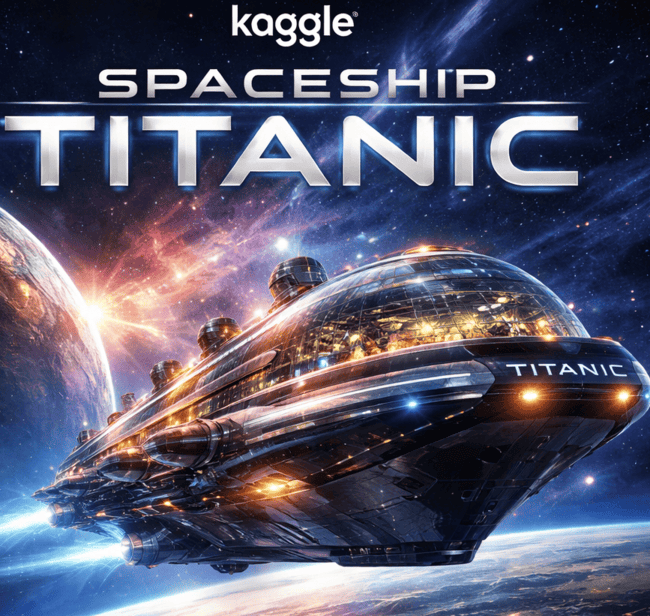

🚀 Spaceship Titanic: A Data Investigation Journey
Final Score: 0.80126 | Kaggle Competition

🎯 The Objective
To predict which passengers of the Spaceship Titanic were "transported" to an alternate dimension after an anomalous incident—a binary classification problem that, at first glance, seems simple, but hid subtle patterns that required forensic investigation of the data.

My goal wasn't just to run a model and hope for the best result. It was to understand the story the data told before letting any algorithm decide for me.

🛠️ O Processo: Detetive de Dados
1. Diagnóstico de nulos com lógica de negócio
Em vez de aplicar fillna(media) cegamente em todas as colunas, tratei cada variável como uma pergunta separada:

VIP: Analisei a proporção de VIPs por HomePlanet e descobri que Earth tinha 0% de VIPs — um padrão determinístico, não aleatório. Isso me permitiu imputar com confiança estatística, em vez de usar a moda geral ignorando o contexto.
Age: Aqui veio a parte mais interessante. Cruzando spendMoney == 0 com CryoSleep == False, encontrei um cluster denso de idades entre 0 e 12 anos (104 registros só na idade 0). A hipótese: crianças não gastam em serviços premium mesmo despertas. Validei calculando a mediana desse subgrupo específico (7 anos) e usei isso como regra de imputação segmentada — muito mais preciso que uma mediana global que diluiria esse sinal.

2. Purposeful Feature Engineering
I broke Cabin into deck, num, and side, applying one-hot encoding.
I created a family_group by extracting surnames from the PassengerId, hypothesizing that families tend to share the same destination.
I aggregated individual spending into spendMoney, creating a feature that captured "consumption behavior" as a proxy for passenger status/activity.

3. Cross-validation of hypotheses, not acceptance on faith

Each imputation decision was tested with groupby().median() and value_counts() before being applied—I wanted to see the pattern in the data, not assume it.

✅ What worked
Segmented imputation of Age (child vs. adult, via spendMoney + CryoSleep) captured a real signal that a simple imputation (global median) would have missed.
The deterministic rule of VIP == False for Earth eliminated noise from a variable that, if poorly handled, could introduce bias.
The decomposition of Cabin into deck and side revealed spatial patterns relevant to the destination.
❌ What didn't work (and what I learned)
Initial attempts to use KNN imputation on Age yielded worse results than the business rules approach—the data had too strong a categorical structure for a purely generic statistical method.
family_group as an isolated feature had a marginal impact—the signal was already partially captured by deck/side, revealing redundancy that I needed to prune to avoid overfitting.

🏁 Conclusion
The score wasn't the result of a complex model or brute-force computing—it was the result of deliberate, tested, and justified decisions at each stage of the pipeline. I prefer a simple model on well-understood data to a complex model on poorly interpreted data.

That, in the end, is the essence of data science: it's not about sophisticated algorithms, it's about asking the right questions before seeking the right answers.

**Library for working with time data types and task parallelization.**

In [2]:
##
import time
from joblib import Parallel, delayed

**model validation**# 

In [3]:
##

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import accuracy_score

print('Loaded the libraries...')

Loaded the libraries...


In [4]:
train_df = pd.read_csv("/kaggle/input/spaceship-titanic/train.csv")
print("Database loaded")

Database loaded


In [5]:
test_df = pd.read_csv("/kaggle/input/spaceship-titanic/test.csv")
print("Test database loaded")

Test database loaded


In [6]:
PassengerId = pd.read_csv("/kaggle/input/spaceship-titanic/test.csv")['PassengerId']
##test_df
PassengerId

0       0013_01
1       0018_01
2       0019_01
3       0021_01
4       0023_01
         ...   
4272    9266_02
4273    9269_01
4274    9271_01
4275    9273_01
4276    9277_01
Name: PassengerId, Length: 4277, dtype: object

In [7]:
# combine = [train_df, test_df]
# print("Training and test database are loaded")

In [8]:
# "After", train_df.shape, test_df.shape, combine[0].shape, combine[1].shape

In [9]:
"After", train_df.shape, test_df.shape

('After', (8693, 14), (4277, 13))

In [10]:
##Check the columns

train_df.columns.values

array(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination',
       'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa',
       'VRDeck', 'Name', 'Transported'], dtype=object)

In [11]:
##Check the first records

train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [12]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [13]:
train_df.tail()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False
8692,9280_02,Europa,False,E/608/S,TRAPPIST-1e,44.0,False,126.0,4688.0,0.0,0.0,12.0,Propsh Hontichre,True


In [14]:
## Brings statistical information about the base

train_df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [15]:
train_df = pd.get_dummies(train_df, columns=['HomePlanet'], prefix='HomePlanet')
train_df

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,False,True,False
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,True,False,False
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,False,True,False
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,False,True,False
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,False,True,False
8689,9278_01,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,True,False,False
8690,9279_01,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,True,False,False
8691,9280_01,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,False,True,False


In [16]:
test_df = pd.get_dummies(test_df, columns=['HomePlanet'], prefix='HomePlanet')
test_df

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
0,0013_01,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning,True,False,False
1,0018_01,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers,True,False,False
2,0019_01,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus,False,True,False
3,0021_01,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter,False,True,False
4,0023_01,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,9266_02,True,G/1496/S,TRAPPIST-1e,34.0,False,0.0,0.0,0.0,0.0,0.0,Jeron Peter,True,False,False
4273,9269_01,False,NaN,TRAPPIST-1e,42.0,False,0.0,847.0,17.0,10.0,144.0,Matty Scheron,True,False,False
4274,9271_01,True,D/296/P,55 Cancri e,NaN,False,0.0,0.0,0.0,0.0,0.0,Jayrin Pore,False,False,True
4275,9273_01,False,D/297/P,NaN,NaN,False,0.0,2680.0,0.0,0.0,523.0,Kitakan Conale,False,True,False


In [17]:
## Correlation of columns to analyse

train_df.select_dtypes(include=['float64', 'bool']).corr()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
Age,1.000000,0.068723,0.130421,0.033133,0.123970,0.101007,-0.075026,-0.202348,0.219793,0.016273
RoomService,0.068723,1.000000,-0.015889,0.054480,0.010080,-0.019581,-0.244611,-0.139361,-0.068098,0.248013
FoodCourt,0.130421,-0.015889,1.000000,-0.014228,0.221891,0.227995,0.046566,-0.211176,0.369477,-0.126142
ShoppingMall,0.033133,0.054480,-0.014228,1.000000,0.013879,-0.007322,0.010141,-0.069880,-0.021282,0.112464
Spa,0.123970,0.010080,0.221891,0.013879,1.000000,0.153821,-0.221131,-0.157018,0.269178,-0.089063
VRDeck,0.101007,-0.019581,0.227995,-0.007322,0.153821,1.000000,-0.207075,-0.153930,0.284801,-0.113128
Transported,-0.075026,-0.244611,0.046566,0.010141,-0.221131,-0.207075,1.000000,-0.169019,0.176916,0.019544
HomePlanet_Earth,-0.202348,-0.139361,-0.211176,-0.069880,-0.157018,-0.153930,-0.169019,1.000000,-0.604411,-0.534195
HomePlanet_Europa,0.219793,-0.068098,0.369477,-0.021282,0.269178,0.284801,0.176916,-0.604411,1.000000,-0.287022
HomePlanet_Mars,0.016273,0.248013,-0.126142,0.112464,-0.089063,-0.113128,0.019544,-0.534195,-0.287022,1.000000


In [18]:
train_df.dtypes

PassengerId           object
CryoSleep             object
Cabin                 object
Destination           object
Age                  float64
VIP                   object
RoomService          float64
FoodCourt            float64
ShoppingMall         float64
Spa                  float64
VRDeck               float64
Name                  object
Transported             bool
HomePlanet_Earth        bool
HomePlanet_Europa       bool
HomePlanet_Mars         bool
dtype: object

<Axes: >

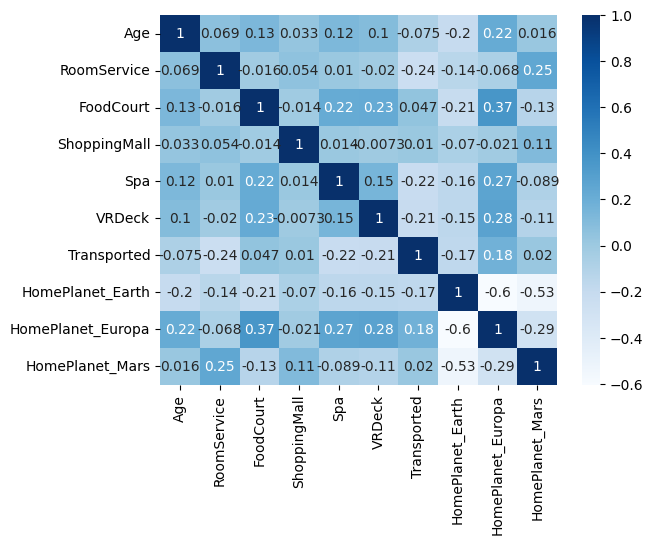

In [19]:
##Heatmap of columns correlation to analyse

sns.heatmap(train_df.select_dtypes(include=['float64', 'bool']).corr(), cmap="Blues", annot=True)

In [20]:
train_df.head()

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,False,True,False
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,True,False,False
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,False,True,False
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,False,True,False
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,True,False,False


In [21]:
##Total records

print("Total de: ",train_df['PassengerId'].count(), " registros")

Total de:  8693  registros


In [22]:
## Check for nulls in train_df base by column

train_df.isnull().sum().sort_values(ascending=False)

CryoSleep            217
ShoppingMall         208
VIP                  203
Name                 200
Cabin                199
VRDeck               188
Spa                  183
FoodCourt            183
Destination          182
RoomService          181
Age                  179
PassengerId            0
Transported            0
HomePlanet_Earth       0
HomePlanet_Europa      0
HomePlanet_Mars        0
dtype: int64

In [23]:
train_df['Cabin'].isna().sum()

np.int64(199)

In [24]:
train_df[train_df['Cabin'].isna()]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
15,0012_01,False,NaN,TRAPPIST-1e,31.0,False,32.0,0.0,876.0,0.0,0.0,Justie Pooles,False,True,False,False
93,0101_01,True,NaN,TRAPPIST-1e,31.0,False,0.0,0.0,0.0,0.0,0.0,Book Trad,True,False,False,True
103,0110_01,False,NaN,TRAPPIST-1e,32.0,False,0.0,410.0,6.0,3929.0,764.0,Graviph Aloubtled,False,False,True,False
222,0239_01,False,NaN,TRAPPIST-1e,37.0,False,637.0,0.0,0.0,92.0,319.0,Diedow Resty,False,False,False,True
227,0244_01,True,NaN,TRAPPIST-1e,43.0,False,0.0,0.0,0.0,0.0,0.0,Froos Sad,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8209,8772_02,False,NaN,55 Cancri e,53.0,False,0.0,1127.0,0.0,3939.0,NaN,Naosura Motled,False,False,True,False
8475,9057_01,False,NaN,55 Cancri e,36.0,True,132.0,3479.0,0.0,3786.0,0.0,Coxan Statch,False,False,True,False
8485,9069_03,True,NaN,55 Cancri e,25.0,False,0.0,0.0,0.0,0.0,0.0,Bath Brakeng,True,False,True,False
8509,9081_03,True,NaN,TRAPPIST-1e,1.0,False,0.0,0.0,0.0,0.0,0.0,Beula Clemondsey,False,True,False,False


deck/num/side

In [25]:
train_df.groupby('Cabin').size().sort_values(ascending=False).reset_index(name='quantidade')


,Cabin,quantidade
0,G/734/S,8
1,G/109/P,7
2,D/176/S,7
3,B/11/S,7
4,C/137/S,7
...,...,...
6555,F/1244/S,1
6556,F/1243/S,1
6557,F/1243/P,1
6558,F/1242/S,1


## Ungroup Cabin column to deck/num/side in train_df base

In [26]:
train_df[['deck','num','side']] = train_df['Cabin'].str.split('/', expand=True)

In [27]:
test_df[['deck','num','side']] = test_df['Cabin'].str.split('/', expand=True)

In [28]:
train_df[['family_group','family_group_number']] = train_df['PassengerId'].str.split('_', expand=True)

In [29]:
test_df[['family_group','family_group_number']] = test_df['PassengerId'].str.split('_', expand=True)

In [30]:
# 1. Extrair o sobrenome do campo Name
train_df['Last_name'] = train_df['Name'].str.split(' ').str[-1]

In [31]:
# 1. Extrair o sobrenome do campo Name
test_df['Last_name'] = test_df['Name'].str.split(' ').str[-1]

In [32]:
train_df['Name'] = train_df['Name'].fillna('Unknown Unknown')
train_df['Last_name'] = train_df['Name'].str.split(' ').str[-1]

In [33]:
test_df['Name'] = test_df['Name'].fillna('Unknown Unknown')
test_df['Last_name'] = test_df['Name'].str.split(' ').str[-1]

In [34]:
train_df.isna().sum()

PassengerId              0
CryoSleep              217
Cabin                  199
Destination            182
Age                    179
VIP                    203
RoomService            181
FoodCourt              183
ShoppingMall           208
Spa                    183
VRDeck                 188
Name                     0
Transported              0
HomePlanet_Earth         0
HomePlanet_Europa        0
HomePlanet_Mars          0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [35]:
train_df['family_group']

0       0001
1       0002
2       0003
3       0003
4       0004
        ... 
8688    9276
8689    9278
8690    9279
8691    9280
8692    9280
Name: family_group, Length: 8693, dtype: object

Passengers from the same group tend to have the same HomePlanet/Destination/Cabin.

In [36]:
train_df[
    ( train_df['CryoSleep'].isnull() ) 
    & ( train_df['ShoppingMall'].isnull() ) 
    # & ( train_df['HomePlanet'].isnull() ) 
    & ( train_df['Cabin'].isnull() ) 
    | ( train_df['Destination'].isnull() ) 
]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
47,0045_02,True,F/10/P,NaN,19.0,False,0.0,0.0,0.0,0.0,...,True,False,False,True,F,10,P,0045,02,Chmad
128,0138_02,False,E/5/P,NaN,34.0,False,0.0,22.0,0.0,564.0,...,False,True,False,False,E,5,P,0138,02,Gambs
139,0152_01,False,F/32/P,NaN,41.0,False,0.0,0.0,0.0,0.0,...,False,True,False,False,F,32,P,0152,01,Estron
347,0382_01,False,G/64/P,NaN,23.0,False,348.0,0.0,0.0,4.0,...,False,False,False,False,G,64,P,0382,01,Floydendley
430,0462_01,True,G/67/S,NaN,50.0,False,0.0,0.0,0.0,0.0,...,False,True,False,False,G,67,S,0462,01,Sosanturney
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8372,8956_02,True,G/1453/P,NaN,20.0,False,0.0,0.0,0.0,0.0,...,True,True,False,False,G,1453,P,8956,02,Bonnondry
8551,9130_01,True,F/1765/S,NaN,41.0,False,0.0,0.0,0.0,0.0,...,True,False,False,True,F,1765,S,9130,01,Corte
8616,9195_02,True,F/1779/S,NaN,33.0,False,0.0,0.0,0.0,0.0,...,True,False,False,True,F,1779,S,9195,02,Purle
8621,9197_02,False,C/308/P,NaN,41.0,True,0.0,7964.0,0.0,3238.0,...,False,False,True,False,C,308,P,9197,02,Platch


In [37]:
train_df.loc[ :,  
    ( train_df.columns != 'PassengerId' ) 
    & ( train_df.columns != 'Name' ) 
    & ( train_df.columns != 'Cabin' ) 
]

,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
0,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,False,True,False,B,0,P,0001,01,Ofracculy
1,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,True,False,False,F,0,S,0002,01,Vines
2,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,False,True,False,A,0,S,0003,01,Susent
3,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,False,True,False,A,0,S,0003,02,Susent
4,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,True,False,False,F,1,S,0004,01,Santantines
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,False,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,False,False,True,False,A,98,P,9276,01,Noxnuther
8689,True,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,False,True,False,False,G,1499,S,9278,01,Mondalley
8690,False,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,True,True,False,False,G,1500,S,9279,01,Connon
8691,False,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,False,False,True,False,E,608,S,9280,01,Hontichre


In [38]:
# train_df['total_money'] = train_df['RoomService'] + train_df['FoodCourt'] + train_df['ShoppingMall'] + train_df['Spa'] + train_df['VRDeck']

In [39]:
# test_df['total_money'] = test_df['RoomService'] + test_df['FoodCourt'] + test_df['ShoppingMall'] + test_df['Spa'] + test_df['VRDeck']

In [40]:
## Median values by columns

# train_df.median()[1:]

In [41]:
test_df.select_dtypes(include=['number']).median()[1:]

RoomService     0.0
FoodCourt       0.0
ShoppingMall    0.0
Spa             0.0
VRDeck          0.0
dtype: float64

In [42]:
## Info values ( Column, Non-Null, Count, Dtype ) by columns

train_df.info()
print('_'*40)
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PassengerId          8693 non-null   object 
 1   CryoSleep            8476 non-null   object 
 2   Cabin                8494 non-null   object 
 3   Destination          8511 non-null   object 
 4   Age                  8514 non-null   float64
 5   VIP                  8490 non-null   object 
 6   RoomService          8512 non-null   float64
 7   FoodCourt            8510 non-null   float64
 8   ShoppingMall         8485 non-null   float64
 9   Spa                  8510 non-null   float64
 10  VRDeck               8505 non-null   float64
 11  Name                 8693 non-null   object 
 12  Transported          8693 non-null   bool   
 13  HomePlanet_Earth     8693 non-null   bool   
 14  HomePlanet_Europa    8693 non-null   bool   
 15  HomePlanet_Mars      8693 non-null   b

In [43]:
## Ungroup family from code and add to dataframe to know how many families and correlate with survivors
## train_df

# train_df['family_group'] = train_df['PassengerId'].str.split("_", n = 1, expand = True)[0]

In [44]:
## Ungroup family from code and add to dataframe to know how many families and correlate with survivors
## train_df

# test_df['family_group'] = test_df['PassengerId'].str.split("_", n = 1, expand = True)[0]

In [45]:
train_df['Spa']

0          0.0
1        549.0
2       6715.0
3       3329.0
4        565.0
         ...  
8688    1643.0
8689       0.0
8690       1.0
8691     353.0
8692       0.0
Name: Spa, Length: 8693, dtype: float64

In [46]:
train_df

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,False,False,True,False,B,0,P,0001,01,Ofracculy
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,...,True,True,False,False,F,0,S,0002,01,Vines
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,False,False,True,False,A,0,S,0003,01,Susent
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,...,False,False,True,False,A,0,S,0003,02,Susent
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,...,True,True,False,False,F,1,S,0004,01,Santantines
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,...,False,False,True,False,A,98,P,9276,01,Noxnuther
8689,9278_01,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,...,False,True,False,False,G,1499,S,9278,01,Mondalley
8690,9279_01,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,...,True,True,False,False,G,1500,S,9279,01,Connon
8691,9280_01,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,...,False,False,True,False,E,608,S,9280,01,Hontichre


In [47]:
##Total de grupos com mais de um status para Transported

train_df.groupby('family_group_number').agg({'Transported': 'count'}).reset_index().query('Transported > 2')

,family_group_number,Transported
0,01,6217
1,02,1412
2,03,571
3,04,231
4,05,128
5,06,75
6,07,46
7,08,13


In [48]:
train_df[ train_df['family_group_number'] == '01' ]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,False,False,True,False,B,0,P,0001,01,Ofracculy
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,...,True,True,False,False,F,0,S,0002,01,Vines
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,False,False,True,False,A,0,S,0003,01,Susent
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,...,True,True,False,False,F,1,S,0004,01,Santantines
5,0005_01,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,...,True,True,False,False,F,0,P,0005,01,Hinetthews
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8685,9275_01,False,A/97/P,TRAPPIST-1e,0.0,False,0.0,0.0,0.0,0.0,...,True,False,True,False,A,97,P,9275,01,Conable
8688,9276_01,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,...,False,False,True,False,A,98,P,9276,01,Noxnuther
8689,9278_01,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,...,False,True,False,False,G,1499,S,9278,01,Mondalley
8690,9279_01,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,...,True,True,False,False,G,1500,S,9279,01,Connon


<Axes: xlabel='CryoSleep,Transported'>

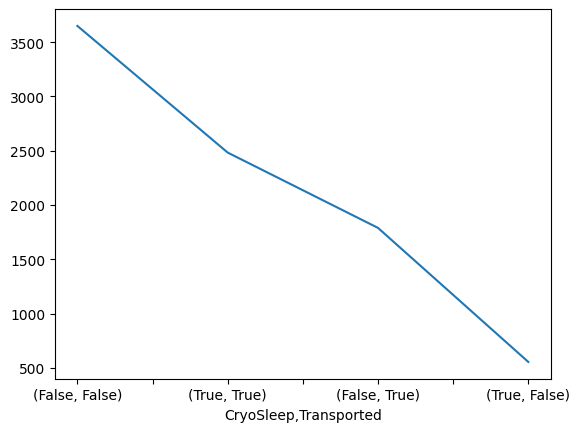

In [49]:
train_df[[ 'CryoSleep', 'Transported' ]].value_counts().plot()

In [50]:
##We have found that children under 12 years old have no expenses. Any child missing this information may have a total expense of 0.

train_df[(train_df['Age'] < 12) & (train_df['RoomService'] != 0) & (train_df['FoodCourt'] != 0) & (train_df['ShoppingMall'] !=0 ) & (train_df['Spa'] != 0) & (train_df['VRDeck'] != 0)]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name


In [51]:
##Now we will input the value 0 to all nan and null children in all services for the train.


train_df.loc[(train_df['Age'] < 12), ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']] = 0
train_df.loc[(train_df['Age'] < 18), ['VIP']] = False

In [52]:
##


test_df.loc[(test_df['Age'] < 12), ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']] = 0
test_df.loc[(test_df['Age'] < 18), ['VIP']] = False

In [53]:
##We found that all records in the VIP column for individuals aged 17 or younger were filled.
train_df[(train_df['Age'] < 18) & (train_df['VIP'] == True)]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name


In [54]:
##Constatamos que Todos os registros de colunas monetárias para crianças até 12 anos foram imputados 0.

train_df[(train_df['Age'] < 12) & (train_df['Spa'].isnull())]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name


In [55]:
## Notamos que uma grande amostra de pessoas do Planeta Natal Europa estava em criogenia. Testamos a condição oposta.
# train_df[(train_df['HomePlanet'] != 'Europa') & (train_df['CryoSleep'] == False)]

We checked the age range of people using Homeplanet and VIP. And we discovered that VIPs are only in the 18 to 73 age range.

In [56]:
# np.sort(train_df[(train_df['HomePlanet'] == 'Mars') & (train_df['VIP'] == True)]['Age'].unique())

In [57]:
##We checked the age range of people using Homeplanet and VIP. And we discovered that VIPs are only in the 18 to 73 age range.

# np.sort(test_df[(test_df['HomePlanet'] == 'Mars') & (test_df['VIP'] == True)]['Age'].unique())

In [58]:
train_df[['family_group','PassengerId']].groupby('family_group')

In [59]:
test_df[['family_group','PassengerId']].groupby('family_group')

In [60]:
##train_df.isna().sum()
test_df.isna().sum()

PassengerId              0
CryoSleep               93
Cabin                  100
Destination             92
Age                     91
VIP                     84
RoomService             75
FoodCourt               98
ShoppingMall            93
Spa                     93
VRDeck                  69
Name                     0
HomePlanet_Earth         0
HomePlanet_Europa        0
HomePlanet_Mars          0
deck                   100
num                    100
side                   100
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [61]:
train_df.groupby("family_group").count()

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Name,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group_number,Last_name
family_group,,,,,,,,,,,,,,,,,,,,,
0001,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
0002,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
0003,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
0004,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
0005,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9275,3,2,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
9276,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
9278,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [62]:
##We consulted all families that have at least one member on Cryosleep and those with more than one member.

family_group = train_df[train_df['CryoSleep'].isnull() & train_df.groupby('family_group')['family_group'].transform('size').gt(1)].sort_values('family_group')['family_group'].unique()
family_group

array(['0099', '0110', '0290', '0348', '0433', '0454', '0568', '0712',
       '0770', '0794', '1116', '1453', '1500', '1624', '1712', '1865',
       '1874', '1882', '2019', '2135', '2234', '2291', '2347', '2384',
       '2558', '2595', '2760', '2822', '3029', '3060', '3163', '3189',
       '3272', '3301', '3422', '3439', '3476', '3489', '3608', '3609',
       '3714', '3747', '3962', '4006', '4066', '4108', '4258', '4315',
       '4371', '4401', '4446', '4569', '4603', '4606', '4680', '4741',
       '4932', '4981', '5090', '5205', '5447', '5552', '5625', '5756',
       '5855', '5927', '6035', '6039', '6066', '6139', '6285', '6309',
       '6324', '6405', '6444', '6525', '6585', '6662', '6674', '6675',
       '6741', '6787', '6827', '6899', '7083', '7186', '7402', '7584',
       '7604', '7697', '7848', '7872', '7891', '7902', '8015', '8119',
       '8252', '8276', '8339', '8366', '8431', '8574', '8719', '8728',
       '8944', '9197', '9227', '9275'], dtype=object)

In [63]:
##We consulted all families that have at least one member on Cryosleep and those with more than one member.

family_group_test = test_df[train_df['CryoSleep'].isnull() & test_df.groupby('family_group')['family_group'].transform('size').gt(1)].sort_values('family_group')['family_group'].unique()
family_group_test

/tmp/ipykernel_23/698042810.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  family_group_test = test_df[train_df['CryoSleep'].isnull() & test_df.groupby('family_group')['family_group'].transform('size').gt(1)].sort_values('family_group')['family_group'].unique()


array(['0230', '0489', '0584', '0827', '0943', '1301', '1422', '1477',
       '1492', '1629', '2108', '2344', '2976', '3008', '3037', '3122',
       '3290', '3368', '3494', '4133', '4298', '4523', '5241', '5329',
       '5789', '6260', '6288', '6612', '6700', '6986', '7100', '7329',
       '7348', '7582', '8181', '8340', '8400', '8793', '8913'],
      dtype=object)

In [64]:
##I took an isolated case to create a filter that could capture rows that match the first row, `family_group`, and are not null.

train_df[(train_df['family_group'] == '0099') & (train_df['Cabin'].notnull())][:1]['Cabin']

91    F/19/P
Name: Cabin, dtype: object

In [65]:
#Estou atribuindo ao dataset o valor filtrado pelo código da família à cabine do primeiro membro da família diferente de nulo para todos que estiverem nulos



def cabinByFamilyGroup(base_df, groups):
    inicial = time.time()
    for group in groups:
        cabin_notnull = base_df[(base_df['family_group'] == group) & (base_df['Cabin'].notnull())]
        if len(cabin_notnull) > 0:
            cabin_str = cabin_notnull.iloc[0]['Cabin']
            base_df.loc[(base_df['family_group'] == group ) & ( base_df['Cabin'].isnull() ), 'Cabin'] = cabin_str

    print(" inicial train: ",inicial," ,Final train",time.time()," Duração train: ",time.time() - inicial)       
            
            
#cabinByFamilyGroup(train_df)  
#cabinByFamilyGroup(test_df)  


In [66]:
def process_group_parallel(train_df, groups):
    cabin_notnull = train_df[(train_df['family_group'] == group) & (train_df['Cabin'].notnull())]
    if len(cabin_notnull) > 0:
        cabin_str = cabin_notnull.iloc[0]['Cabin']
        train_df.loc[ ( train_df['family_group'] == group & train_df['Cabin'].isnull() ), 'Cabin'] = cabin_str

def cabinByFamilyGroup_parallel(train_df, groups):
    inicial = time.time()
    #groups = train_df['family_group'].unique()
    Parallel(n_jobs=-1, backend='multiprocessing')(delayed(process_group_parallel)(train_df, groups) for group in groups)
    print(" inicial train: ",inicial," ,Final train",time.time()," Duração train: ",time.time() - inicial)

In [67]:
#inicial = time.time()
cabinByFamilyGroup(test_df, family_group_test) 
#print(" inicial: ",inicial," ,Final ",time.time()," Duração: ",time.time() - inicial)

 inicial train:  1793797362.142216  ,Final train 1793797362.2343087  Duração train:  0.09209322929382324


In [68]:
#inicial = time.time()
cabinByFamilyGroup(train_df, family_group)  
#print(" inicial: ",inicial," ,Final ",time.time()," Duração: ",time.time() - inicial)

 inicial train:  1793797362.3005242  ,Final train 1793797362.6624637  Duração train:  0.3619399070739746


In [69]:
##Here we confirm that everything is correct. It should return 0 lines.
train_df[(train_df['family_group'] == '0110') & (train_df['Cabin'].isnull())]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name


In [70]:
train_df.groupby("family_group")['PassengerId'].count()

family_group
0001    1
0002    1
0003    2
0004    1
0005    1
       ..
9275    3
9276    1
9278    1
9279    1
9280    2
Name: PassengerId, Length: 6217, dtype: int64

In [71]:
train_df.isnull().sum()

PassengerId              0
CryoSleep              217
Cabin                  188
Destination            182
Age                    179
VIP                    158
RoomService            162
FoodCourt              171
ShoppingMall           189
Spa                    169
VRDeck                 165
Name                     0
Transported              0
HomePlanet_Earth         0
HomePlanet_Europa        0
HomePlanet_Mars          0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [72]:
train_df[(train_df['Destination'] == 'TRAPPIST-1e') 
             & (train_df['RoomService'] == 0)
            & (train_df['FoodCourt'] == 0)
            & (train_df['ShoppingMall'] == 0)
            & (train_df['Spa'] == 0)
            & (train_df['VRDeck'] == 0)
            & (train_df['Transported'] == True)
        & (train_df['Transported'].isnull())]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name


In [73]:
train_df [(train_df['RoomService'] == 0)
            | (train_df['FoodCourt'] == 0)
            | (train_df['ShoppingMall'] == 0)
            | (train_df['Spa'] == 0)
            | (train_df['VRDeck'] == 0)]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,False,False,True,False,B,0,P,0001,01,Ofracculy
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,False,False,True,False,A,0,S,0003,01,Susent
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,...,False,False,True,False,A,0,S,0003,02,Susent
5,0005_01,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,...,True,True,False,False,F,0,P,0005,01,Hinetthews
6,0006_01,False,F/2/S,TRAPPIST-1e,26.0,False,42.0,1539.0,3.0,0.0,...,True,True,False,False,F,2,S,0006,01,Jacostaffey
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,...,False,False,True,False,A,98,P,9276,01,Noxnuther
8689,9278_01,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,...,False,True,False,False,G,1499,S,9278,01,Mondalley
8690,9279_01,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,...,True,True,False,False,G,1500,S,9279,01,Connon
8691,9280_01,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,...,False,False,True,False,E,608,S,9280,01,Hontichre


In [74]:
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'].isnull()), 'VRDeck'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'].isnull()) & (train_df['VRDeck'] == 0), 'Spa'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'].isnull()) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'ShoppingMall'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'].isnull()) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'FoodCourt'] = 0
train_df.loc [(train_df['RoomService'].isnull()) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'RoomService'] = 0

In [75]:
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'].isnull()), 'VRDeck'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'].isnull()) & (test_df['VRDeck'] == 0), 'Spa'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'].isnull()) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'ShoppingMall'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'].isnull()) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'FoodCourt'] = 0
test_df.loc [(test_df['RoomService'].isnull()) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'RoomService'] = 0

In [76]:
train_df.isna().sum()

PassengerId              0
CryoSleep              217
Cabin                  188
Destination            182
Age                    179
VIP                    158
RoomService            107
FoodCourt              108
ShoppingMall           108
Spa                    117
VRDeck                 109
Name                     0
Transported              0
HomePlanet_Earth         0
HomePlanet_Europa        0
HomePlanet_Mars          0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [77]:
train_df[(train_df['PassengerId']=='0006_02')]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
7,0006_02,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,...,True,True,False,False,G,0,S,0006,02,Jacostaffey


In [78]:
train_df['Destination'].unique()

array(['TRAPPIST-1e', 'PSO J318.5-22', '55 Cancri e', nan], dtype=object)

In [79]:
##Total de grupos familiares

np.count_nonzero(train_df['family_group'].unique().astype('int') )

6217

In [80]:
## Group the data by family group whether or not it was transported

##train_df[train_df[['family_group','Transported']].groupby(['family_group'], as_index=False).count().sort_values(by='family_group', ascending=True)['Transported'] > 2]

In [81]:
# ##Compare origin and destination (Earth) #Compare origin and destination (Europe)
# earth_trappist = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
# earth_55cancri_e = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
# earth_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

In [82]:
# ##Compare origin and destination (Europe)
# europa_trappist = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
# europa_55cancri_e = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
# europa_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

In [83]:
# ##Compare origin and destination (Europe)
# mars_trappist = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
# mars_55cancri_e = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
# mars_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

Here I tried to relate HomePlanet with Destination

to get the count for each destination and check

if there is a correlation with the target column Transported

Conclusion: I found no correlation.

In [84]:
# home_planet_destination = dict()
# home_planet_destination["earth_trappist"] = (earth_trappist)
# home_planet_destination["earth_55cancri_e"] = (earth_55cancri_e)
# home_planet_destination["earth_pso_j318_22"] = (earth_pso_j318_22)
# home_planet_destination["europa_trappist"] = (europa_trappist)
# home_planet_destination["europa_55cancri_e"] = (europa_55cancri_e)
# home_planet_destination["europa_pso_j318_22"] = (europa_pso_j318_22)
# home_planet_destination["mars_trappist"] = (mars_trappist)
# home_planet_destination["mars_55cancri_e"] = (mars_55cancri_e)
# home_planet_destination["mars_pso_j318_22"] = (mars_pso_j318_22)   

# home_planet_destination

In [85]:
# train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "55 Cancri e") & (train_df["Transported"] == False) ]["PassengerId"].count()

In [86]:
##Look up deck, side, number using the deck.
deck_num_side = train_df[['deck','side','num']][train_df[['deck','num','side']]["deck"] == "G"].sort_values(by=['deck','side','num'])
display(deck_num_side.drop_duplicates())

,deck,side,num
19,G,P,0
40,G,P,1
5835,G,P,1000
5839,G,P,1001
5843,G,P,1002
...,...,...,...
5792,G,S,994
5812,G,S,995
5820,G,S,996
5824,G,S,998


In [87]:
"""
print("Passageiros total:",train_df[['deck','PassengerId']].groupby("deck").count())
print("Passageiros transportados: ",train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count())
print("Percentual de passageiros transportados por deck: ",train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count() * 100
/ train_df[['deck','PassengerId']].groupby("deck").count(), "%" )


tabularTransportadosPorDeck = pd.Dataframe({"Percentual de passageiros transportados por deck: ":train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count() * 100
/ train_df[['deck','PassengerId']].groupby("deck").count()})
"""


'\nprint("Passageiros total:",train_df[[\'deck\',\'PassengerId\']].groupby("deck").count())\nprint("Passageiros transportados: ",train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count())\nprint("Percentual de passageiros transportados por deck: ",train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count() * 100\n/ train_df[[\'deck\',\'PassengerId\']].groupby("deck").count(), "%" )\n\n\ntabularTransportadosPorDeck = pd.Dataframe({"Percentual de passageiros transportados por deck: ":train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count() * 100\n/ train_df[[\'deck\',\'PassengerId\']].groupby("deck").count()})\n'

In [88]:
##Quantidade família por deck
train_df[["family_group","deck"]].groupby(["deck"]).count()

,family_group
deck,
A,256
B,779
C,747
D,478
E,876
F,2794
G,2559
T,5


In [89]:
##Family quantity per deck
##train_df[["family_group","deck"]].groupby(["family_group"]).count() > 1

In [90]:
train_df['deck'].unique()

array(['B', 'F', 'A', 'G', nan, 'E', 'D', 'C', 'T'], dtype=object)

In [91]:
train_df['num'].value_counts().unique()

array([28, 22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10,  9,  8,  7,
        6,  5,  4,  3,  2,  1])

In [92]:
train_df.isna().sum()

PassengerId              0
CryoSleep              217
Cabin                  188
Destination            182
Age                    179
VIP                    158
RoomService            107
FoodCourt              108
ShoppingMall           108
Spa                    117
VRDeck                 109
Name                     0
Transported              0
HomePlanet_Earth         0
HomePlanet_Europa        0
HomePlanet_Mars          0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [93]:
###train_df['PassengerId'].groupby('family_group').count()

In [94]:
## These are the cabins, Shopping Mall and Room Service where passengers were transported

cabin_transported = train_df[['Cabin','Transported']].groupby(['Cabin'], as_index=False).mean().sort_values(by='Transported', ascending=False)
ShoppingMall_transported = train_df[['ShoppingMall','Transported']].groupby(['ShoppingMall'], as_index=False).mean().sort_values(by='Transported', ascending=False)
RoomService_transported = train_df[['RoomService','Transported']].groupby(['RoomService'], as_index=False).mean().sort_values(by='Transported', ascending=False)

In [95]:
## These are the cabins, Shopping Mall and Room Service that had no passengers transported

cabin_not_transported = pd.DataFrame()
ShoppingMall_not_transported = pd.DataFrame()
RoomService_not_transported =pd.DataFrame()

cabin_not_transported['cabin_not_transported'] = cabin_transported.loc[cabin_transported['Transported'] == 0].Cabin.unique()
ShoppingMall_not_transported['ShoppingMall_not_transported'] = ShoppingMall_transported.loc[ShoppingMall_transported['Transported'] == 0].ShoppingMall.unique()
RoomService_not_transported['RoomService_not_transported'] = RoomService_transported.loc[RoomService_transported['Transported'] == 0].RoomService.unique()


In [96]:
print(" Cabins in which people were not transported: ", np.count_nonzero(cabin_not_transported) ) 
print(" ShoppingMall_transported where people were not transported: ", np.count_nonzero(ShoppingMall_not_transported) )
print(" RoomService in which people were not transported: ", np.count_nonzero(RoomService_not_transported) )

 Cabins in which people were not transported:  3166
 ShoppingMall_transported where people were not transported:  499
 RoomService in which people were not transported:  851


In [97]:
cabin_not_transported

,cabin_not_transported
0,E/198/S
1,E/269/S
2,E/197/S
3,G/245/P
4,E/194/S
...,...
3161,F/1216/P
3162,F/1217/P
3163,F/1218/P
3164,F/1221/P


In [98]:
# test_df['cabin_not_transported'] = 0
# test_df['ShoppingMall_not_transported'] = 0
# test_df['RoomService_not_transported'] = 0
test_df.head()

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Name,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
0,0013_01,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,...,Nelly Carsoning,True,False,False,G,3,S,0013,01,Carsoning
1,0018_01,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,...,Lerome Peckers,True,False,False,F,4,S,0018,01,Peckers
2,0019_01,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,...,Sabih Unhearfus,False,True,False,C,0,S,0019,01,Unhearfus
3,0021_01,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,...,Meratz Caltilter,False,True,False,C,1,S,0021,01,Caltilter
4,0023_01,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,...,Brence Harperez,True,False,False,F,5,S,0023,01,Harperez


In [99]:
# ## Alternative code below
# # Find rows where the cabin is not transported
# mask = train_df['Cabin'].isin(cabin_not_transported['cabin_not_transported'])

# # Set the values of the 'cabin_not_transported' column to 1 where the mask is True, 0 otherwise
# train_df.loc[mask, 'cabin_not_transported'] = 1
# train_df.loc[~mask, 'cabin_not_transported'] = 0


In [100]:
# ## Alternative code below
# # Find rows where the cabin is not transported
# mask = test_df['Cabin'].isin(cabin_not_transported['cabin_not_transported'])

# # Set the values of the 'cabin_not_transported' column to 1 where the mask is True, 0 otherwise
# test_df.loc[mask, 'cabin_not_transported'] = 1
# test_df.loc[~mask, 'cabin_not_transported'] = 0


Alternative code below
Find rows where the ShoppingMall is not transported
This is interesting. Could this feature be causing harm to the final result?

In [101]:

# mask = train_df['ShoppingMall'].isin(ShoppingMall_not_transported['ShoppingMall_not_transported'])

# # Set the values of the 'ShoppingMall_not_transported' column to 1 where the mask is True, 0 otherwise
# train_df.loc[mask, 'ShoppingMall_not_transported'] = 1
# train_df.loc[~mask, 'ShoppingMall_not_transported'] = 0

In [102]:
# ## Alternative code below
# # Find rows where the ShoppingMall is not transported
# mask = test_df['ShoppingMall'].isin(ShoppingMall_not_transported['ShoppingMall_not_transported'])

# # Set the values of the 'ShoppingMall_not_transported' column to 1 where the mask is True, 0 otherwise
# test_df.loc[mask, 'ShoppingMall_not_transported'] = 1
# test_df.loc[~mask, 'ShoppingMall_not_transported'] = 0

In [103]:
# ## Alternative code below
# # Find rows where the RoomService is not transported
# mask = train_df['RoomService'].isin(RoomService_not_transported['RoomService_not_transported'])

# # Set the values of the 'RoomService_not_transported' column to 1 where the mask is True, 0 otherwise
# train_df.loc[mask, 'RoomService_not_transported'] = 1
# train_df.loc[~mask, 'RoomService_not_transported'] = 0

In [104]:
# ## Alternative code below
# # Find rows where the RoomService is not transported
# mask = test_df['RoomService'].isin(RoomService_not_transported['RoomService_not_transported'])

# # Set the values of the 'RoomService_not_transported' column to 1 where the mask is True, 0 otherwise
# test_df.loc[mask, 'RoomService_not_transported'] = 1
# test_df.loc[~mask, 'RoomService_not_transported'] = 0

In [105]:
## See if the column is populated correctly by checking the registration by sampling

train_df[train_df['Cabin'] == 'G/328/S']

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
1929,2063_01,True,G/328/S,PSO J318.5-22,38.0,False,0.0,0.0,0.0,0.0,...,False,True,False,False,G,328,S,2063,01,Leonaldez


In [106]:
# ## See if the column is populated correctly by checking the registration by sampling

# train_df[train_df['ShoppingMall_not_transported'] == 1]

In [107]:
## See if the column is populated correctly by checking the registration by sampling

train_df[train_df['RoomService'] == 570.]

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
8241,8805_01,False,F/1815/P,PSO J318.5-22,37.0,False,570.0,0.0,7.0,107.0,...,False,True,False,False,F,1815,P,8805,01,Rasmussony


In [108]:
## Create column with people who were in these cabins that were not affected

cabin_cryosleeped = train_df[train_df['CryoSleep'] == True]['Cabin'].unique()

total_cabin_criosleeps = np.count_nonzero(cabin_cryosleeped)

print(" Cabines para CryoSleep: ", np.count_nonzero(cabin_cryosleeped))

 Cabines para CryoSleep:  2439


In [109]:
## Total cabins for cryosleeps

total_cabin = np.count_nonzero( train_df['Cabin'].unique() )

print("Total de cabines: ",total_cabin," - cabines para criosleeps: ",total_cabin_criosleeps," -  Percentual cabines criosleeps: ", (total_cabin_criosleeps * 100 / total_cabin)," %")

Total de cabines:  6561  - cabines para criosleeps:  2439  -  Percentual cabines criosleeps:  37.174211248285324  %


In [110]:
## Total cabins

total_cabin = np.count_nonzero( train_df['Cabin'].unique() )

print("Total de cabines: ",total_cabin," - cabines para criosleeps: ",total_cabin_criosleeps," -  Percentual cabines criosleeps: ", (total_cabin_criosleeps * 100 / total_cabin)," %")

Total de cabines:  6561  - cabines para criosleeps:  2439  -  Percentual cabines criosleeps:  37.174211248285324  %


In [111]:
##  Create grid with correlation comparisons between bank columns

##g = sns.PairGrid(train_df, hue="Transported")
##g.map_diag(sns.scatterplot)
##g.map_offdiag(sns.scatterplot)
##g.add_legend()

print("continue...")

continue...


In [112]:
## Premises:
## Some cabins were not transported
## Drop PassengerId, Name columns that have no information
## Family_group has no null values
## Spa, VRDeck, ShoppingMall, Vip have a low correlation with transported passengers (Really?).
## Who're CryoSleep don't spend money

In [113]:
train_df['Transported']

0       False
1        True
2       False
3       False
4        True
        ...  
8688    False
8689    False
8690     True
8691    False
8692     True
Name: Transported, Length: 8693, dtype: bool

In [114]:
train_df.head()

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,False,False,True,False,B,0,P,0001,01,Ofracculy
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,...,True,True,False,False,F,0,S,0002,01,Vines
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,False,False,True,False,A,0,S,0003,01,Susent
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,...,False,False,True,False,A,0,S,0003,02,Susent
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,...,True,True,False,False,F,1,S,0004,01,Santantines


<Axes: >

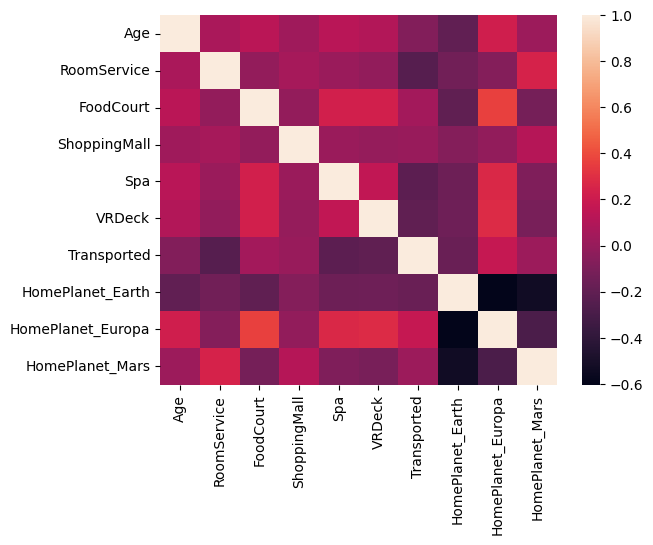

In [115]:
## Numerical correlation between columns

sns.heatmap(train_df.select_dtypes(include=['float64', 'bool']).corr())

In [116]:
## Convert columns from object to float

train_df['family_group'] = train_df['family_group'].str.replace(',','.').astype(float)
train_df['num'] = train_df['num'].str.replace(',','.').astype(float)

In [117]:
## Convert columns from object to float

test_df['family_group'] = test_df['family_group'].str.replace(',','.').astype(float)
test_df['num'] = test_df['num'].str.replace(',','.').astype(float)

In [118]:
## Let's check if there were passengers alone

groupby_family_group = train_df.groupby('family_group').count()['PassengerId']

print("Total de famílias: ",groupby_family_group.count(), " Percentual de grupos de pessoas sozinhas: ",( ( groupby_family_group.loc[groupby_family_group == 1].count() * 100 ) / groupby_family_group.count() )," %"  )

Total de famílias:  6217  Percentual de grupos de pessoas sozinhas:  77.28808106803925  %


In [119]:
#Let's work about null values

test_df.isnull().sum()

PassengerId              0
CryoSleep               93
Cabin                   97
Destination             92
Age                     91
VIP                     84
RoomService             54
FoodCourt               67
ShoppingMall            62
Spa                     52
VRDeck                  42
Name                     0
HomePlanet_Earth         0
HomePlanet_Europa        0
HomePlanet_Mars          0
deck                   100
num                    100
side                   100
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [120]:
##Complete the NAN in deck, num and side

train_df["deck"].fillna("Unknown")
train_df["num"].fillna("Unknown")
train_df["side"].fillna("Unknown")

0       P
1       S
2       S
3       S
4       S
       ..
8688    P
8689    S
8690    S
8691    S
8692    S
Name: side, Length: 8693, dtype: object

In [121]:
##Complete the NAN in deck, num and side

test_df["deck"].fillna("Unknown")
test_df["num"].fillna("Unknown")
test_df["side"].fillna("Unknown")

0             S
1             S
2             S
3             S
4             S
         ...   
4272          S
4273    Unknown
4274          P
4275          P
4276          S
Name: side, Length: 4277, dtype: object

In [122]:
##  Filling NaN, null or etc values in train_df

train_df["CryoSleep"].fillna(False)
train_df["Age"].fillna(train_df["Age"].median())
train_df["VIP"].fillna(False)
##test_df["HomePlanet"].fillna(0)

train_df["RoomService"].fillna( float( train_df["RoomService"].mean() ) )
train_df["FoodCourt"].fillna( float( train_df["FoodCourt"].mean() ) )
train_df["ShoppingMall"].fillna( float( train_df["ShoppingMall"].mean() ) )
train_df["Spa"].fillna( float( train_df["Spa"].mean() ) )
train_df["VRDeck"].fillna( float( train_df["VRDeck"].mean() ) )
train_df = train_df.fillna(train_df.mode())

/tmp/ipykernel_23/968550383.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_df["CryoSleep"].fillna(False)
/tmp/ipykernel_23/968550383.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_df["VIP"].fillna(False)


In [123]:
##  Filling NaN, null or etc values in train_df

test_df["CryoSleep"].fillna(False)
test_df["Age"].fillna(train_df["Age"].median() )
test_df["VIP"].fillna(False)
##test_df["HomePlanet"].fillna(0)

test_df["RoomService"].fillna( float( test_df["RoomService"].mean()  ) )
test_df["FoodCourt"].fillna( float( test_df["FoodCourt"].mean() ))
test_df["ShoppingMall"].fillna( float( test_df["ShoppingMall"].mean() ) )
test_df["Spa"].fillna( float( test_df["Spa"].mean() ) )
test_df["VRDeck"].fillna( float( test_df["VRDeck"].mean() ) )
test_df = test_df.fillna(test_df.mode())

/tmp/ipykernel_23/4173459767.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_df["CryoSleep"].fillna(False)
/tmp/ipykernel_23/4173459767.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_df["VIP"].fillna(False)


In [124]:
# ##  Filling NaN, null or etc values in test_df

# test_df["CryoSleep"].fillna(False)
# test_df["Age"].fillna(train_df["Age"].median())
# test_df["VIP"].fillna(False)
# ##test_df["HomePlanet"].fillna(0)

# test_df["RoomService"].fillna( float( test_df["RoomService"].mean() ), inplace=True)
# test_df["FoodCourt"].fillna( float( test_df["FoodCourt"].mean() ), inplace=True)
# test_df["ShoppingMall"].fillna( float( test_df["ShoppingMall"].mean() ), inplace=True)
# test_df["Spa"].fillna( float( test_df["Spa"].mean() ), inplace=True)
# test_df["VRDeck"].fillna( float( test_df["VRDeck"].mean() ), inplace=True)
# test_df = test_df.fillna(test_df.mode())

In [125]:
# train_df['spendMoney'] = train_df['RoomService'] + train_df['FoodCourt'] + train_df['ShoppingMall'] + train_df['Spa']
# train_df

In [126]:
# test_df['spendMoney'] = test_df['RoomService'] + test_df['FoodCourt'] + test_df['ShoppingMall'] + test_df['Spa']
# test_df

In [127]:
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

for col in spend_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

train_df['spendMoney'] = train_df[spend_cols].sum(axis=1)
test_df['spendMoney'] = test_df[spend_cols].sum(axis=1)

In [128]:
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

for df in [train_df, test_df]:
    df['spendMoney'] = df[spend_cols].sum(axis=1)
    for col in spend_cols:
        df[f'{col}_ratio'] = df[col] / (df['spendMoney'] + 1e-6)  # evita divisão por zero


In [129]:
train_df.shape

(8693, 28)

In [130]:
##Funny. If the guy is a VIP, he is not from the earth
##display( train_df.query( 'HomePlanet == "Earth" and VIP == True' ) ) 
# display( test_df.query( 'HomePlanet == "Earth" and VIP == True' ) ) 

In [131]:
##If you're from the Earth, you're not a VIP.
# train_df.loc[(train_df['VIP'].isnull()) & (train_df['HomePlanet'] == 'Earth'),'VIP'] = 0
# test_df.loc[(test_df['VIP'].isnull()) & (test_df['HomePlanet'] == 'Earth'),'VIP'] = 0

In [132]:
##Who're cryosleep don't spend money. Who're spending money don't are cryosleep

train_df.loc[(train_df['CryoSleep'].isna()) & (train_df['spendMoney'] == 0), 'CryoSleep'] = 1
train_df.loc[(train_df['CryoSleep'].isna()) & (train_df['spendMoney'] > 0), 'CryoSleep'] = 0

In [133]:
test_df.loc[(test_df['CryoSleep'].isna()) & (test_df['spendMoney'] == 0), 'CryoSleep'] = 1
test_df.loc[(test_df['CryoSleep'].isna()) & (test_df['spendMoney'] > 0), 'CryoSleep'] = 0

In [134]:
train_df.loc[train_df['CryoSleep'].isna(),['RoomService','FoodCourt','ShoppingMall','VRDeck', 'Spa']]

,RoomService,FoodCourt,ShoppingMall,VRDeck,Spa


In [135]:
train_df.isna().sum()

PassengerId              0
CryoSleep                0
Cabin                  188
Destination            182
Age                    179
VIP                    158
RoomService              0
FoodCourt                0
ShoppingMall             0
Spa                      0
VRDeck                   0
Name                     0
Transported              0
HomePlanet_Earth         0
HomePlanet_Europa        0
HomePlanet_Mars          0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
spendMoney               0
RoomService_ratio        0
FoodCourt_ratio          0
ShoppingMall_ratio       0
Spa_ratio                0
VRDeck_ratio             0
dtype: int64

In [136]:
##  View the HomePlanet column to see what values are contained

# train_df['HomePlanet'].unique()

In [137]:
## Create a list with the values that will be replaced and the values that will replace

# HomePlanet_mapping = {"Europa":1,"Earth":2,"Mars":3}
# HomePlanet_mapping

In [138]:
for df in [train_df, test_df]:
    df['num'] = pd.to_numeric(df['num'], errors='coerce')
    df['num'] = df['num'].fillna(df.groupby('deck')['num'].transform('median'))
    df['num'] = df['num'].fillna(df['num'].median())


In [139]:
train_df = pd.get_dummies(train_df, columns=['deck'], prefix='deck')
train_df

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Spa_ratio,VRDeck_ratio,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,0.000000,0.000000,False,True,False,False,False,False,False,False
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,...,0.745924,0.059783,False,False,False,False,False,True,False,False
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,0.646730,0.004719,True,False,False,False,False,False,False,False
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,...,0.643161,0.037287,True,False,False,False,False,False,False,False
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,...,0.517874,0.001833,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,...,0.192479,0.008669,True,False,False,False,False,False,False,False
8689,9278_01,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,...,0.000000,0.000000,False,False,False,False,False,False,True,False
8690,9279_01,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,...,0.000534,0.000000,False,False,False,False,False,False,True,False
8691,9280_01,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,...,0.076127,0.697649,False,False,False,False,True,False,False,False


In [140]:
test_df = pd.get_dummies(test_df, columns=['deck'], prefix='deck')
test_df

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Spa_ratio,VRDeck_ratio,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T
0,0013_01,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,...,0.000000,0.000000,False,False,False,False,False,False,True,False
1,0018_01,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,...,0.996822,0.000000,False,False,False,False,False,True,False,False
2,0019_01,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,...,0.000000,0.000000,False,False,True,False,False,False,False,False
3,0021_01,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,...,0.024400,0.078862,False,False,True,False,False,False,False,False
4,0023_01,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,...,0.000000,0.000000,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,9266_02,True,G/1496/S,TRAPPIST-1e,34.0,False,0.0,0.0,0.0,0.0,...,0.000000,0.000000,False,False,False,False,False,False,True,False
4273,9269_01,False,NaN,TRAPPIST-1e,42.0,False,0.0,847.0,17.0,10.0,...,0.009823,0.141454,False,False,False,False,False,False,False,False
4274,9271_01,True,D/296/P,55 Cancri e,NaN,False,0.0,0.0,0.0,0.0,...,0.000000,0.000000,False,False,False,True,False,False,False,False
4275,9273_01,False,D/297/P,NaN,NaN,False,0.0,2680.0,0.0,0.0,...,0.000000,0.163284,False,False,False,True,False,False,False,False


In [141]:
print([c for c in train_df.columns if 'deck' in c.lower()])

['VRDeck', 'VRDeck_ratio', 'deck_A', 'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_T']


In [142]:
## Convert categorical / HomePlanet data to numeric in train_df

# train_df = train_df.replace(HomePlanet_mapping)
# train_df.head()

In [143]:
## Convert categorical / HomePlanet data to numeric in test_df

# test_df = test_df.replace(HomePlanet_mapping)
# test_df.head()

Calculate the average age of people who had no expenses. They might be children.

In [144]:
# Regra 1: CryoSleep == False e spendMoney == 0 -> provável criança
median_child_age = train_df.loc[
    (train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == False), 'Age'
].median()

median_child_age

7.0

In [145]:
train_df.columns

Index(['PassengerId', 'CryoSleep', 'Cabin', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name',
       'Transported', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'num', 'side', 'family_group', 'family_group_number',
       'Last_name', 'spendMoney', 'RoomService_ratio', 'FoodCourt_ratio',
       'ShoppingMall_ratio', 'Spa_ratio', 'VRDeck_ratio', 'deck_A', 'deck_B',
       'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_T'],
      dtype='object')

In [146]:
homeplanet_cols = ['HomePlanet_Earth', 'HomePlanet_Europa', 'HomePlanet_Mars']

for df in [train_df, test_df]:
    mask_child = (df['Age'].isna()) & (df['spendMoney'] == 0) & (df['CryoSleep'] == False)
    df.loc[mask_child, 'Age'] = median_child_age

    # Reconstrói o rótulo do planeta a partir das dummies, só para o groupby
    homeplanet_label = df[homeplanet_cols].idxmax(axis=1)

    # Para os nulos restantes, usa mediana por HomePlanet
    df['Age'] = df['Age'].fillna(
        df.groupby(homeplanet_label)['Age'].transform('median')
    )

    # Fallback final (mediana geral)
    df['Age'] = df['Age'].fillna(df['Age'].median())


In [147]:
# train_df = pd.get_dummies(train_df,columns = ['HomePlanet'])
# train_df

In [148]:
# test_df = pd.get_dummies(test_df,columns = ['HomePlanet'])
# test_df

In [149]:
## Join the modified bases in combine

# combine = [train_df, test_df]
# combine

In [150]:
## Drop PassengerId and Name columns in test_df

##test_df = test_df.drop(['Name'], axis=1)
train_df.head()

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,Spa_ratio,VRDeck_ratio,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,0.000000,0.000000,False,True,False,False,False,False,False,False
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,...,0.745924,0.059783,False,False,False,False,False,True,False,False
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,0.646730,0.004719,True,False,False,False,False,False,False,False
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,...,0.643161,0.037287,True,False,False,False,False,False,False,False
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,...,0.517874,0.001833,False,False,False,False,False,True,False,False


In [151]:
## Analyze the Destinations possibles

#train_df['Destination'].unique()

In [152]:
# destination = {'TRAPPIST-1e':'1','PSO J318.5-22':'2',
#                '55 Cancri e':'3','0':'0','1':'0'}

In [153]:
# train_df = train_df.replace(destination)
# train_df.head()

In [154]:
# test_df = test_df.replace(destination)
# test_df.head()

In [155]:
train_df['Destination'] = train_df['Destination'].fillna('Unknown')
test_df['Destination'] = test_df['Destination'].fillna('Unknown')

In [156]:
test_df = pd.get_dummies(test_df, columns=['Destination'], prefix='dest')

In [157]:
train_df = pd.get_dummies(train_df, columns=['Destination'], prefix='dest')

In [158]:
# Garantir que treino e teste tenham as mesmas colunas
test_df = test_df.reindex(columns=train_df.columns, fill_value=0)

In [159]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 38 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PassengerId          8693 non-null   object 
 1   CryoSleep            8693 non-null   object 
 2   Cabin                8505 non-null   object 
 3   Age                  8693 non-null   float64
 4   VIP                  8535 non-null   object 
 5   RoomService          8693 non-null   float64
 6   FoodCourt            8693 non-null   float64
 7   ShoppingMall         8693 non-null   float64
 8   Spa                  8693 non-null   float64
 9   VRDeck               8693 non-null   float64
 10  Name                 8693 non-null   object 
 11  Transported          8693 non-null   bool   
 12  HomePlanet_Earth     8693 non-null   bool   
 13  HomePlanet_Europa    8693 non-null   bool   
 14  HomePlanet_Mars      8693 non-null   bool   
 15  num                  8693 non-null   f

In [160]:
# ## Create a list with the values that will be replaced and the values that will replace

# Side_mapping = {"P":1,"S":2,"0":0}
# Side_mapping

In [161]:
# ## Create a list with the values that will be replaced and the values that will replace

# Deck_mapping = {"B":1,"F":2,"A":3, 'G':4, 'E':5,'D':6,'C':7,'T':8,'0':0}
# Deck_mapping

In [162]:
# ## Convert categorical/Deck data to numeric in test_df

# # test_df = test_df.replace(Deck_mapping)
# test_df = test_df.replace(Side_mapping)
# test_df.head()

In [163]:
# ## Convert categorical/Deck data to numeric in train_df

# # train_df = train_df.replace(Deck_mapping)
# train_df = train_df.replace(Side_mapping)
# train_df.head()

In [164]:
for df in [train_df, test_df]:
    df["side_missing"] = df["side"].isna().astype(int)  # flag de ausência
    df["side"] = df["side"].map({"P": 1, "S": 2}).fillna(0)

In [165]:
train_df.head()

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,deck_D,deck_E,deck_F,deck_G,deck_T,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,0001_01,False,B/0/P,39.0,False,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,False,False,True,False,0
1,0002_01,False,F/0/S,24.0,False,109.0,9.0,25.0,549.0,44.0,...,False,False,True,False,False,False,False,True,False,0
2,0003_01,False,A/0/S,58.0,True,43.0,3576.0,0.0,6715.0,49.0,...,False,False,False,False,False,False,False,True,False,0
3,0003_02,False,A/0/S,33.0,False,0.0,1283.0,371.0,3329.0,193.0,...,False,False,False,False,False,False,False,True,False,0
4,0004_01,False,F/1/S,16.0,False,303.0,70.0,151.0,565.0,2.0,...,False,False,True,False,False,False,False,True,False,0


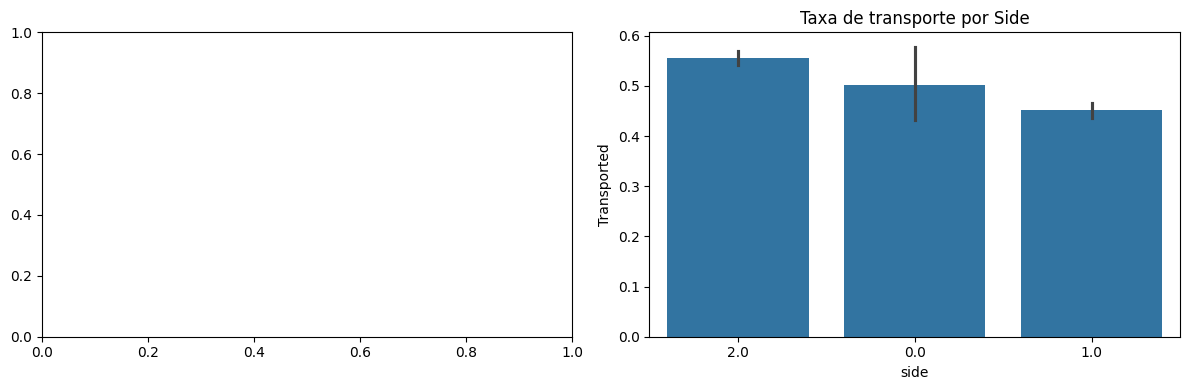

In [166]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ordena os decks pela taxa de transporte (maior → menor)
# deck_order = train_df.groupby('deck')['Transported'].mean().sort_values(ascending=False).index

# Ordena os sides pela taxa de transporte (maior → menor)
side_order = train_df.groupby('side')['Transported'].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# sns.barplot(data=train_df, x='deck', y='Transported', order=deck_order, ax=axes[0])
# axes[0].set_title('Taxa de transporte por Deck')

sns.barplot(data=train_df, x='side', y='Transported', order=side_order, ax=axes[1])
axes[1].set_title('Taxa de transporte por Side')

plt.tight_layout()
plt.show()


In [167]:
test_df['VRDeck'].mode()

0    0.0
Name: VRDeck, dtype: float64

In [168]:
test_df = test_df.drop("Name", axis=1)
##test_df = test_df.drop("Destination", axis=1)
# test_df = test_df.drop("Cabin", axis=1)
##test_df = test_df.drop("deck", axis=1)
##test_df = test_df.drop("side", axis=1)
test_df

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,deck_D,deck_E,deck_F,deck_G,deck_T,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,0013_01,True,G/3/S,27.0,False,0.0,0.0,0.0,0.0,0.0,...,False,False,False,True,False,False,False,True,False,0
1,0018_01,False,F/4/S,19.0,False,0.0,9.0,0.0,2823.0,0.0,...,False,False,True,False,False,False,False,True,False,0
2,0019_01,True,C/0/S,31.0,False,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,True,False,False,False,0
3,0021_01,False,C/1/S,38.0,False,0.0,6652.0,0.0,181.0,585.0,...,False,False,False,False,False,False,False,True,False,0
4,0023_01,False,F/5/S,20.0,False,10.0,0.0,635.0,0.0,0.0,...,False,False,True,False,False,False,False,True,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,9266_02,True,G/1496/S,34.0,False,0.0,0.0,0.0,0.0,0.0,...,False,False,False,True,False,False,False,True,False,0
4273,9269_01,False,NaN,42.0,False,0.0,847.0,17.0,10.0,144.0,...,False,False,False,False,False,False,False,True,False,1
4274,9271_01,True,D/296/P,27.0,False,0.0,0.0,0.0,0.0,0.0,...,True,False,False,False,False,True,False,False,False,0
4275,9273_01,False,D/297/P,32.0,False,0.0,2680.0,0.0,0.0,523.0,...,True,False,False,False,False,False,False,False,True,0


In [169]:
## Transform boolean variable True/False into 1/0

train_df['Transported'] = train_df['Transported'].astype(int)

In [170]:
train_df['CryoSleep'] = train_df['CryoSleep'].astype(int)

In [171]:
train_df.loc[train_df['VIP'].isna(),:]

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,deck_D,deck_E,deck_F,deck_G,deck_T,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
145,0165_01,1,F/37/P,35.0,NaN,0.0,0.0,0.0,0.0,0.0,...,False,False,True,False,False,False,False,True,False,0
566,0593_01,0,D/24/P,28.0,NaN,43.0,152.0,182.0,1.0,2005.0,...,True,False,False,False,False,False,False,True,False,0
582,0607_01,0,C/22/P,37.0,NaN,27.0,654.0,10.0,881.0,9568.0,...,False,False,False,False,False,False,False,True,False,0
596,0619_01,1,C/24/S,39.0,NaN,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,False,False,True,False,0
646,0679_01,0,G/104/S,20.0,NaN,0.0,215.0,0.0,541.0,0.0,...,False,False,False,True,False,False,False,True,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8428,9003_01,0,F/1744/S,23.0,NaN,2.0,167.0,0.0,0.0,555.0,...,False,False,True,False,False,False,False,True,False,0
8430,9006_01,1,B/343/S,33.0,NaN,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,False,False,True,False,0
8542,9122_01,1,G/1469/S,55.0,NaN,0.0,0.0,0.0,0.0,0.0,...,False,False,False,True,False,True,False,False,False,0
8630,9205_03,1,B/300/P,52.0,NaN,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,False,False,True,False,0


In [172]:
for df in [train_df, test_df]:
    df.loc[df['CryoSleep'] == 1, 'VIP'] = 0

In [173]:
train_df.loc[train_df['VIP'].isna(),:]

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,deck_D,deck_E,deck_F,deck_G,deck_T,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
566,0593_01,0,D/24/P,28.0,NaN,43.0,152.0,182.0,1.0,2005.0,...,True,False,False,False,False,False,False,True,False,0
582,0607_01,0,C/22/P,37.0,NaN,27.0,654.0,10.0,881.0,9568.0,...,False,False,False,False,False,False,False,True,False,0
646,0679_01,0,G/104/S,20.0,NaN,0.0,215.0,0.0,541.0,0.0,...,False,False,False,True,False,False,False,True,False,0
832,0889_02,0,C/32/P,27.0,NaN,1.0,12804.0,0.0,10.0,52.0,...,False,False,False,False,False,True,False,False,False,0
850,0913_01,0,E/51/P,38.0,NaN,0.0,172.0,0.0,5907.0,34.0,...,False,True,False,False,False,True,False,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8297,8860_04,0,E/567/P,33.0,NaN,1054.0,0.0,222.0,22.0,0.0,...,False,True,False,False,False,False,False,True,False,0
8365,8945_02,0,D/270/S,21.0,NaN,3036.0,32.0,0.0,2.0,416.0,...,True,False,False,False,False,False,False,True,False,0
8367,8948_01,0,B/342/S,57.0,NaN,0.0,13.0,0.0,52.0,11325.0,...,False,False,False,False,False,False,False,True,False,0
8428,9003_01,0,F/1744/S,23.0,NaN,2.0,167.0,0.0,0.0,555.0,...,False,False,True,False,False,False,False,True,False,0


In [174]:
# train_df.groupby('HomePlanet')['VIP'].mean()

In [175]:
# train_df.loc[train_df['VIP'] == 1,:]['HomePlanet'].unique()

In [176]:
train_df.groupby('VIP').mean(numeric_only=True)

,CryoSleep,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,HomePlanet_Earth,HomePlanet_Europa,...,deck_D,deck_E,deck_F,deck_G,deck_T,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
VIP,,,,,,,,,,,,,,,,,,,,,
False,0.372638,28.546297,210.588969,411.783787,167.727683,291.348627,272.924522,0.509331,0.540116,0.237490,...,0.052419,0.101034,0.323071,0.302389,0.000594,0.205515,0.090931,0.682515,0.021039,0.022584
True,0.000000,37.550562,518.848315,1964.039326,269.994382,841.910112,1352.792135,0.308989,0.000000,0.623596,...,0.157303,0.084270,0.162921,0.000000,0.000000,0.297753,0.101124,0.589888,0.011236,0.033708


In [177]:
train_df.groupby('VIP')[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'spendMoney']].mean()

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,spendMoney
VIP,,,,,,
False,210.588969,411.783787,167.727683,291.348627,272.924522,1354.373588
True,518.848315,1964.039326,269.994382,841.910112,1352.792135,4947.584270


In [178]:
# pd.crosstab(train_df['VIP'], train_df['HomePlanet'], normalize='index')
# pd.crosstab(train_df['VIP'], train_df['Destination'], normalize='index')

In [179]:
pd.crosstab(train_df['VIP'], train_df['CryoSleep'], normalize='index')
pd.crosstab(train_df['VIP'], train_df['deck'] if 'deck' in train_df.columns else train_df['Cabin'], normalize='index')

Cabin,A/0/P,A/0/S,A/1/S,A/10/P,A/10/S,A/100/S,A/101/S,A/102/S,A/103/S,A/104/S,...,G/996/S,G/998/P,G/998/S,G/999/P,G/999/S,T/0/P,T/1/P,T/2/P,T/2/S,T/3/P
VIP,,,,,,,,,,,,,,,,,,,,,
False,0.000243,0.000121,0.000364,0.000121,0.000121,0.000121,0.000243,0.000121,0.000243,0.000243,...,0.000121,0.000121,0.000121,0.000243,0.000243,0.000121,0.000121,0.000121,0.000121,0.000121
True,0.000000,0.005814,0.000000,0.000000,0.000000,0.005814,0.000000,0.000000,0.005814,0.005814,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


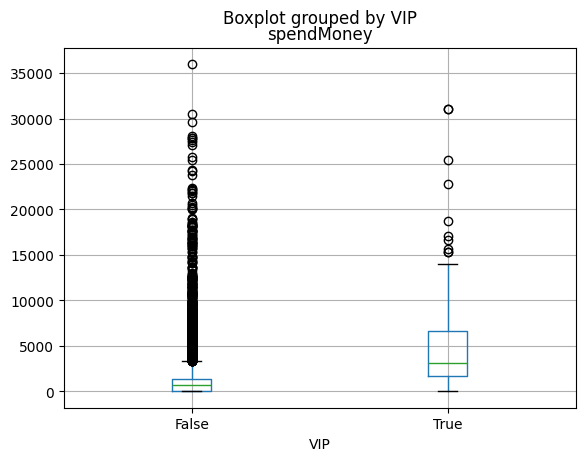

In [180]:
import matplotlib.pyplot as plt

train_df.boxplot(column='spendMoney', by='VIP')
plt.show()

In [181]:
train_df = train_df.copy()
test_df = test_df.copy()

spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

for df in [train_df, test_df]:
    df['spendMoney'] = df[spend_cols].sum(axis=1)
    for col in spend_cols:
        df[f'{col}_ratio'] = df[col] / (df['spendMoney'] + 1e-6)  # evita divisão por zero


In [182]:
train_df.columns

Index(['PassengerId', 'CryoSleep', 'Cabin', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported',
       'HomePlanet_Earth', 'HomePlanet_Europa', 'HomePlanet_Mars', 'num',
       'side', 'family_group', 'family_group_number', 'Last_name',
       'spendMoney', 'RoomService_ratio', 'FoodCourt_ratio',
       'ShoppingMall_ratio', 'Spa_ratio', 'VRDeck_ratio', 'deck_A', 'deck_B',
       'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_T',
       'dest_55 Cancri e', 'dest_PSO J318.5-22', 'dest_TRAPPIST-1e',
       'dest_Unknown', 'side_missing'],
      dtype='object')

In [183]:
combined = pd.concat([train_df.drop(columns=['Transported']), test_df], axis=0)
combined['family_size'] = combined.groupby('family_group')['family_group'].transform('count')
combined['is_alone'] = (combined['family_size'] == 1).astype(int)

fam_map = combined[['PassengerId', 'family_size', 'is_alone']]

train_df = train_df.merge(fam_map, on='PassengerId', how='left')
test_df = test_df.merge(fam_map, on='PassengerId', how='left')


In [184]:
train_df['VIP'] = train_df['VIP'].fillna(0)

In [185]:
test_df['VIP'] = test_df['VIP'].fillna(0)

In [186]:
train_df['VIP'] = train_df['VIP'].astype(int)

In [187]:
test_df['CryoSleep'] = test_df['CryoSleep'].astype(int)

In [188]:
test_df['VIP'] = test_df['VIP'].astype(int)

In [189]:
train_df.dtypes

PassengerId             object
CryoSleep                int64
Cabin                   object
Age                    float64
VIP                      int64
RoomService            float64
FoodCourt              float64
ShoppingMall           float64
Spa                    float64
VRDeck                 float64
Name                    object
Transported              int64
HomePlanet_Earth          bool
HomePlanet_Europa         bool
HomePlanet_Mars           bool
num                    float64
side                   float64
family_group           float64
family_group_number     object
Last_name               object
spendMoney             float64
RoomService_ratio      float64
FoodCourt_ratio        float64
ShoppingMall_ratio     float64
Spa_ratio              float64
VRDeck_ratio           float64
deck_A                    bool
deck_B                    bool
deck_C                    bool
deck_D                    bool
deck_E                    bool
deck_F                    bool
deck_G  

In [190]:
test_df.dtypes

PassengerId             object
CryoSleep                int64
Cabin                   object
Age                    float64
VIP                      int64
RoomService            float64
FoodCourt              float64
ShoppingMall           float64
Spa                    float64
VRDeck                 float64
Transported              int64
HomePlanet_Earth          bool
HomePlanet_Europa         bool
HomePlanet_Mars           bool
num                    float64
side                   float64
family_group           float64
family_group_number     object
Last_name               object
spendMoney             float64
RoomService_ratio      float64
FoodCourt_ratio        float64
ShoppingMall_ratio     float64
Spa_ratio              float64
VRDeck_ratio           float64
deck_A                    bool
deck_B                    bool
deck_C                    bool
deck_D                    bool
deck_E                    bool
deck_F                    bool
deck_G                    bool
deck_T  

In [191]:
featured = [
    'CryoSleep','Destination','Age',
    'VIP','RoomService','FoodCourt','ShoppingMall',
    'Spa','VRDeck','family_group','deck_A',	'deck_B',	'deck_C',	'deck_D',	'deck_E',	'deck_F',	'deck_G',	'deck_T','num',
    'side','cabin_not_transported','ShoppingMall_not_transported',
    'RoomService_not_transported','spendMoney','Transported'
           ]


In [192]:
train_df['Transported'].astype(int)

0       0
1       1
2       0
3       0
4       1
       ..
8688    0
8689    0
8690    1
8691    0
8692    1
Name: Transported, Length: 8693, dtype: int64

In [193]:
train_df.groupby('VIP')['Age'].median()

VIP
0    27.0
1    34.0
Name: Age, dtype: float64

In [194]:
train_df.loc[train_df['Age'].isna(),:]

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,deck_F,deck_G,deck_T,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing,family_size,is_alone


In [195]:
train_df['Age'].isna().sum()

np.int64(0)

In [196]:
train_df.loc[( (train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == 0) ),['spendMoney', 'RoomService',	'FoodCourt', 'ShoppingMall', 'Spa',	'VRDeck', 'Age', 'CryoSleep']]['Age'].value_counts()

Age
0.0     104
7.0      34
4.0      34
8.0      31
3.0      27
11.0     26
9.0      26
2.0      26
12.0     25
10.0     24
1.0      23
6.0      23
5.0      10
26.0      7
28.0      6
19.0      6
22.0      6
25.0      5
21.0      5
37.0      5
20.0      5
31.0      4
27.0      4
29.0      3
32.0      3
38.0      3
35.0      3
53.0      3
44.0      3
36.0      2
57.0      2
56.0      2
39.0      2
33.0      2
14.0      2
30.0      2
18.0      2
54.0      2
40.0      2
71.0      1
34.0      1
16.0      1
48.0      1
52.0      1
45.0      1
51.0      1
24.0      1
49.0      1
60.0      1
13.0      1
59.0      1
17.0      1
41.0      1
Name: count, dtype: int64

In [197]:
median_child_age = train_df.loc[
    (train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == False), 'Age'
].median()

print(median_child_age)

7.0


In [198]:
train_df.loc[(train_df['Age'].isna() & train_df['spendMoney'] == 0 ),:]

,PassengerId,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,deck_F,deck_G,deck_T,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing,family_size,is_alone
0,0001_01,0,B/0/P,39.0,0,0.0,0.0,0.0,0.0,0.0,...,False,False,False,False,False,True,False,0,1,1
1,0002_01,0,F/0/S,24.0,0,109.0,9.0,25.0,549.0,44.0,...,True,False,False,False,False,True,False,0,1,1
2,0003_01,0,A/0/S,58.0,1,43.0,3576.0,0.0,6715.0,49.0,...,False,False,False,False,False,True,False,0,2,0
3,0003_02,0,A/0/S,33.0,0,0.0,1283.0,371.0,3329.0,193.0,...,False,False,False,False,False,True,False,0,2,0
4,0004_01,0,F/1/S,16.0,0,303.0,70.0,151.0,565.0,2.0,...,True,False,False,False,False,True,False,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,0,A/98/P,41.0,1,0.0,6819.0,0.0,1643.0,74.0,...,False,False,False,True,False,False,False,0,1,1
8689,9278_01,1,G/1499/S,18.0,0,0.0,0.0,0.0,0.0,0.0,...,False,True,False,False,True,False,False,0,1,1
8690,9279_01,0,G/1500/S,26.0,0,0.0,0.0,1872.0,1.0,0.0,...,False,True,False,False,False,True,False,0,1,1
8691,9280_01,0,E/608/S,32.0,0,0.0,1049.0,0.0,353.0,3235.0,...,False,False,False,True,False,False,False,0,2,0


In [199]:
train_df[ train_df['dest_PSO J318.5-22'] == 1 ]['Age'].median()

24.0

In [200]:
train_df[ train_df['dest_TRAPPIST-1e'] == 1 ]['Age'].median()

27.0

In [201]:
train_df[ train_df['dest_TRAPPIST-1e'] == 1 ]['Age'].median()

27.0

In [202]:
median_child_age = train_df.loc[(train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == False),:]['Age'].median()

In [203]:
# train_df.groupby('HomePlanet')['Age'].median()

In [204]:
# train_final = train_df[featured]

In [205]:
# train_df['HomePlanet'].value_counts()

In [206]:
train_df.loc[:,['Cabin','num']].isna().sum()

Cabin    188
num        0
dtype: int64

In [207]:
train_final = train_df.select_dtypes(include=['number'])

In [208]:
test_df = test_df.select_dtypes(include=['number'])

In [209]:
train_final.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'num', 'side', 'family_group',
       'spendMoney', 'RoomService_ratio', 'FoodCourt_ratio',
       'ShoppingMall_ratio', 'Spa_ratio', 'VRDeck_ratio', 'side_missing',
       'family_size', 'is_alone'],
      dtype='object')

In [210]:
test_df.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'num', 'side', 'family_group',
       'spendMoney', 'RoomService_ratio', 'FoodCourt_ratio',
       'ShoppingMall_ratio', 'Spa_ratio', 'VRDeck_ratio', 'side_missing',
       'family_size', 'is_alone'],
      dtype='object')

In [211]:
train_final.shape

(8693, 21)

In [212]:
train_final.isna().sum()

CryoSleep             0
Age                   0
VIP                   0
RoomService           0
FoodCourt             0
ShoppingMall          0
Spa                   0
VRDeck                0
Transported           0
num                   0
side                  0
family_group          0
spendMoney            0
RoomService_ratio     0
FoodCourt_ratio       0
ShoppingMall_ratio    0
Spa_ratio             0
VRDeck_ratio          0
side_missing          0
family_size           0
is_alone              0
dtype: int64

In [213]:
train_df.spendMoney

0           0.0
1         736.0
2       10383.0
3        5176.0
4        1091.0
         ...   
8688     8536.0
8689        0.0
8690     1873.0
8691     4637.0
8692     4826.0
Name: spendMoney, Length: 8693, dtype: float64

In [214]:
# for df in [train_df, test_df]:
#     df['Age'] = df['Age'].fillna(
#         df.groupby('HomePlanet')['Age'].transform('median')
#     )
#     # fallback se ainda sobrar nulo (ex: HomePlanet também nulo)
#     df['Age'] = df['Age'].fillna(df['Age'].median())

In [215]:
train_df.head().columns

Index(['PassengerId', 'CryoSleep', 'Cabin', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported',
       'HomePlanet_Earth', 'HomePlanet_Europa', 'HomePlanet_Mars', 'num',
       'side', 'family_group', 'family_group_number', 'Last_name',
       'spendMoney', 'RoomService_ratio', 'FoodCourt_ratio',
       'ShoppingMall_ratio', 'Spa_ratio', 'VRDeck_ratio', 'deck_A', 'deck_B',
       'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_T',
       'dest_55 Cancri e', 'dest_PSO J318.5-22', 'dest_TRAPPIST-1e',
       'dest_Unknown', 'side_missing', 'family_size', 'is_alone'],
      dtype='object')

In [216]:
removed_columns = ['Transported']

In [217]:
##

Y = train_final['Transported']
X = train_final.drop(removed_columns, axis=1)

In [218]:
X.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'num', 'side', 'family_group', 'spendMoney',
       'RoomService_ratio', 'FoodCourt_ratio', 'ShoppingMall_ratio',
       'Spa_ratio', 'VRDeck_ratio', 'side_missing', 'family_size', 'is_alone'],
      dtype='object')

In [219]:
len(X.columns)

20

In [220]:
train_final.shape

(8693, 21)

In [221]:
train_final = train_df[test_df.columns]

In [222]:
X.shape

(8693, 20)

In [223]:
## Split train and test database

X_train_split, X_valid, Y_train_split, Y_valid = train_test_split(X, Y, train_size=0.7, test_size=0.3, random_state=0)
print(" train_test_split feito")


 train_test_split feito


In [224]:
featured

['CryoSleep',
 'Destination',
 'Age',
 'VIP',
 'RoomService',
 'FoodCourt',
 'ShoppingMall',
 'Spa',
 'VRDeck',
 'family_group',
 'deck_A',
 'deck_B',
 'deck_C',
 'deck_D',
 'deck_E',
 'deck_F',
 'deck_G',
 'deck_T',
 'num',
 'side',
 'cabin_not_transported',
 'ShoppingMall_not_transported',
 'RoomService_not_transported',
 'spendMoney',
 'Transported']

In [225]:
train_final.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,num,...,family_group,spendMoney,RoomService_ratio,FoodCourt_ratio,ShoppingMall_ratio,Spa_ratio,VRDeck_ratio,side_missing,family_size,is_alone
0,0,39.0,0,0.0,0.0,0.0,0.0,0.0,0,0.0,...,1.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0,1,1
1,0,24.0,0,109.0,9.0,25.0,549.0,44.0,1,0.0,...,2.0,736.0,0.148098,0.012228,0.033967,0.745924,0.059783,0,1,1
2,0,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,0.0,...,3.0,10383.0,0.004141,0.344409,0.000000,0.646730,0.004719,0,2,0
3,0,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,0.0,...,3.0,5176.0,0.000000,0.247875,0.071677,0.643161,0.037287,0,2,0
4,0,16.0,0,303.0,70.0,151.0,565.0,2.0,1,1.0,...,4.0,1091.0,0.277727,0.064161,0.138405,0.517874,0.001833,0,1,1


In [226]:
X_train_split.shape

(6085, 20)

In [227]:
X_valid.shape

(2608, 20)

In [228]:
# X_test = test_df

In [229]:
X_train_split.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'num', 'side', 'family_group', 'spendMoney',
       'RoomService_ratio', 'FoodCourt_ratio', 'ShoppingMall_ratio',
       'Spa_ratio', 'VRDeck_ratio', 'side_missing', 'family_size', 'is_alone'],
      dtype='object')

In [230]:
X_train_split

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,num,side,family_group,spendMoney,RoomService_ratio,FoodCourt_ratio,ShoppingMall_ratio,Spa_ratio,VRDeck_ratio,side_missing,family_size,is_alone
7289,0,64.0,0,19.0,261.0,208.0,0.0,214.0,1491.0,2.0,7791.0,702.0,0.027066,0.371795,0.296296,0.000000,0.304843,0,1,1
2709,0,24.0,0,0.0,2.0,25.0,0.0,707.0,601.0,1.0,2901.0,734.0,0.000000,0.002725,0.034060,0.000000,0.963215,0,2,0
6803,0,44.0,0,0.0,0.0,16.0,72.0,4304.0,461.0,1.0,7186.0,4392.0,0.000000,0.000000,0.003643,0.016393,0.979964,0,3,0
3731,0,34.0,0,0.0,847.0,14.0,0.0,0.0,758.0,2.0,4001.0,861.0,0.000000,0.983740,0.016260,0.000000,0.000000,0,7,0
6333,0,13.0,0,0.0,0.0,0.0,0.0,0.0,429.0,1.0,6699.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4373,1,32.0,0,0.0,0.0,0.0,0.0,0.0,154.0,1.0,4655.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0,2,0
7891,0,22.0,0,0.0,0.0,6.0,0.0,733.0,1620.0,2.0,8423.0,739.0,0.000000,0.000000,0.008119,0.000000,0.991881,0,1,1
4859,0,29.0,0,523.0,0.0,21.0,4.0,811.0,330.0,2.0,5185.0,1359.0,0.384842,0.000000,0.015453,0.002943,0.596762,0,1,1
3264,0,0.0,0,0.0,0.0,0.0,0.0,0.0,574.0,1.0,3499.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0,4,0


In [231]:
## Transform boolean variable True/False into 1/0

y_valid = Y_valid.astype(int)

In [232]:
y_valid

3601    1
6057    1
2797    0
7110    0
8579    1
       ..
7081    1
2873    1
3420    1
535     1
5117    0
Name: Transported, Length: 2608, dtype: int64

In [233]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_split)
X_valid_scaled = scaler.transform(X_valid)

In [234]:
## Logistic regression
logreg = LogisticRegression(solver='lbfgs', max_iter=10000)
logreg.fit(X_train_scaled, Y_train_split)
Y_pred = logreg.predict(X_valid_scaled)

acc_log_score = round(logreg.score(X_valid_scaled, Y_valid) * 100, 2)

acc_log_score

78.49

In [235]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='lbfgs', max_iter=10000, random_state=42))
])

In [236]:
scores = cross_val_score(pipeline, X_train_scaled, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79539852 0.78471652 0.80197206 0.80772391 0.79539852]
Média: 0.7970419063270338
Desvio padrão: 0.007690622157303245


In [237]:
lr_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",lr_accuracy_score)

 Accuracy score:  78.48926380368098


In [238]:
# import optuna
# from sklearn.svm import SVC
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.model_selection import StratifiedKFold, cross_val_score

# import optuna
# from sklearn.model_selection import StratifiedKFold, cross_val_score


In [239]:
# study_svm.optimize(objective, n_trials=50)

In [240]:
# def objective(trial):
#     # Kernel categórico: cada um tem um subconjunto de hiperparâmetros relevantes
#     kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])

#     params = {
#         'C': trial.suggest_float('C', 1e-3, 1e3, log=True),
#         'kernel': kernel,
#         'gamma': trial.suggest_float('gamma', 1e-4, 1e1, log=True),
#         'random_state': 42,
#         'probability': False,  # True só se precisar de predict_proba (deixa mais lento)
#     }

#     # 'degree' só é usado pelo kernel 'poly'
#     if kernel == 'poly':
#         params['degree'] = trial.suggest_int('degree', 2, 5)
#         params['coef0'] = trial.suggest_float('coef0', 0.0, 10.0)
#     elif kernel == 'sigmoid':
#         params['coef0'] = trial.suggest_float('coef0', 0.0, 10.0)

#     # SVM é sensível a escala: Pipeline garante que o scaler
#     # seja ajustado só no fold de treino em cada iteração do CV (evita leakage)
#     model = Pipeline([
#         ('scaler', StandardScaler()),
#         ('svm', SVC(**params)),
#     ])

#     skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#     scores = cross_val_score(model, X_train_split, Y_train_split, cv=skf, scoring='accuracy', n_jobs=-1)

#     return scores.mean()

In [241]:
# study_svm = optuna.create_study(
#     direction='maximize',
#     storage='sqlite:///optuna_svm.db',
#     study_name='svm_spaceship',
#     load_if_exists=True
# )

In [242]:
# print('Melhor score:', study_svm.best_value)
# print('Melhores params:', study_svm.best_params)

In [243]:
# best_params_svm = study_svm.best_params

In [244]:
best_params_svm_fixed = {'C': 88.63222036408084, 'coef0': 1.0991839769918084, 'degree': 3, 'gamma': 0.0034326504090994876, 'kernel': 'poly'}

In [245]:
##
svc = SVC(**best_params_svm_fixed, random_state=42, max_iter=5000)
svc.fit(X_train_scaled, Y_train_split)
Y_pred = svc.predict(X_valid_scaled)

acc_svc_score = round(svc.score(X_valid_scaled, y_valid) * 100, 2)
acc_svc_score

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


78.87

In [246]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(**best_params_svm_fixed, random_state=42, max_iter=5000))  # ou -1 (sem limite)
])

In [247]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Scores por fold: [0.79293344 0.78225144 0.80279376 0.81758422 0.79622021]
Média: 0.7983566146261298
Desvio padrão: 0.01168538296442477


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


In [248]:
svc_accuracy_score = accuracy_score(y_valid, Y_pred) * 100
print("Accuracy score: ", svc_accuracy_score)

Accuracy score:  78.87269938650306


In [249]:
##
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train_scaled, Y_train_split)
Y_pred = knn.predict(X_valid_scaled)

acc_knn_score = round(knn.score(X_valid_scaled, Y_valid) * 100, 2)

acc_knn_score

76.34

In [250]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors = 3))
])

In [251]:
scores = cross_val_score(pipeline, X_train_scaled, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.76088743 0.74445357 0.75349219 0.76088743 0.75020542]
Média: 0.7539852095316352
Desvio padrão: 0.006335032133901866


In [252]:
knn_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",knn_accuracy_score)

 Accuracy score:  76.3420245398773


In [253]:
##
gaussian = GaussianNB()
gaussian.fit(X_train_scaled, Y_train_split)
Y_pred = gaussian.predict(X_valid_scaled)

acc_gaussian_score = round(gaussian.score(X_valid_scaled, Y_valid) * 100, 2)

acc_gaussian_score

75.46

In [254]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GaussianNB())
])

In [255]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [256]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.76006574 0.73541495 0.76253081 0.78718159 0.77074774]
Média: 0.7631881676253082
Desvio padrão: 0.016818826954150497


In [257]:
gaussian_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",gaussian_accuracy_score)

 Accuracy score:  75.4601226993865


In [258]:
##

perceptron = Perceptron()
perceptron.fit(X_train_scaled, Y_train_split)
Y_pred = perceptron.predict(X_valid_scaled)

acc_perceptron_score = round(perceptron.score(X_valid_scaled, Y_valid) * 100, 2)

acc_perceptron_score

70.28

In [259]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Perceptron())
])

In [260]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [261]:
perceptron_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",perceptron_accuracy_score)

 Accuracy score:  70.28374233128835


In [262]:

##
linear_svc = LinearSVC(max_iter=480000)
linear_svc.fit(X_train_scaled, Y_train_split)
Y_pred = linear_svc.predict(X_valid_scaled)

acc_linear_svc_score = round(linear_svc.score(X_valid_scaled, Y_valid) * 100, 2)

acc_linear_svc_score

78.37

In [263]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearSVC(max_iter=480000, random_state=42))
])

In [264]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [265]:
print("Scores:", scores)
print("Média:", scores.mean())

Scores: [0.79868529 0.78142975 0.80197206 0.81265407 0.79704191]
Média: 0.7983566146261298


In [266]:
linear_svc_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",linear_svc_accuracy_score)

 Accuracy score:  78.37423312883436


In [267]:
##
sgd = SGDClassifier( max_iter=1000, random_state=42)
sgd.fit(X_train_scaled, Y_train_split)
Y_pred = sgd.predict(X_valid_scaled)

acc_sgd_score = round(sgd.score(X_valid_scaled, Y_valid) * 100, 2)

acc_sgd_score

76.8

In [268]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SGDClassifier(max_iter=1000, random_state=42))
])

In [269]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [270]:
print("Scores:", scores)
print("Média:", scores.mean())

Scores: [0.78471652 0.7641742  0.78307313 0.80279376 0.78800329]
Média: 0.7845521774856203


In [271]:
sgd_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",sgd_accuracy_score)

 Accuracy score:  76.8021472392638


In [272]:
##
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train_split, Y_train_split)
Y_pred = decision_tree.predict(X_valid)

acc_decision_tree_score = round(decision_tree.score(X_valid, Y_valid) * 100, 2)

acc_decision_tree_score

72.24

In [273]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', DecisionTreeClassifier())
])

In [274]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [275]:
print("Scores:", scores)
print("Média:", scores.mean())

Scores: [0.72801972 0.73623665 0.73870173 0.73294988 0.7411668 ]
Média: 0.7354149548069021


In [276]:
dt_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",dt_accuracy_score)

 Accuracy score:  72.23926380368098


In [277]:
##
random_forest = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)
random_forest.fit(X_train_split, Y_train_split)
Y_pred = random_forest.predict(X_valid)

random_forest.score(X_train_split, Y_train_split)
acc_random_forest_score = round(random_forest.score(X_valid, Y_valid) * 100, 2)

acc_random_forest_score

78.64

In [278]:
scores = cross_val_score(random_forest, X_train_split, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79539852 0.77896467 0.80197206 0.82087099 0.79375514]
Média: 0.7981922760887429
Desvio padrão: 0.013607389675914199


In [279]:
rf_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",rf_accuracy_score)

 Accuracy score:  78.64263803680981


In [280]:
X_train_split.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6085 entries, 7289 to 2732
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CryoSleep           6085 non-null   int64  
 1   Age                 6085 non-null   float64
 2   VIP                 6085 non-null   int64  
 3   RoomService         6085 non-null   float64
 4   FoodCourt           6085 non-null   float64
 5   ShoppingMall        6085 non-null   float64
 6   Spa                 6085 non-null   float64
 7   VRDeck              6085 non-null   float64
 8   num                 6085 non-null   float64
 9   side                6085 non-null   float64
 10  family_group        6085 non-null   float64
 11  spendMoney          6085 non-null   float64
 12  RoomService_ratio   6085 non-null   float64
 13  FoodCourt_ratio     6085 non-null   float64
 14  ShoppingMall_ratio  6085 non-null   float64
 15  Spa_ratio           6085 non-null   float64
 16  VRDeck_r

In [281]:
# import lightgbm as lgb
# import xgboost as xgb

In [282]:
# #Let’s examine the best parameters for this model on this dataset. 
# #Running them all at once would likely be too computationally intensive, so we’ll test them one by one.




# def objective(trial):
#     params = {
#         'objective': 'binary',
#         'metric': 'binary_logloss',
#         'num_leaves': trial.suggest_int('num_leaves', 15, 63),
#         'max_depth': trial.suggest_int('max_depth', 3, 10),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
#         'min_child_samples': trial.suggest_int('min_child_samples', 10, 60),
#         'subsample': trial.suggest_float('subsample', 0.6, 1.0),
#         'subsample_freq': 1,
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
#         'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
#         'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
#         'n_estimators': 1000,
#         'random_state': 42,
#         'n_jobs': -1,
#         'verbosity': -1,
#     }

#     model = lgb.LGBMClassifier(**params)

#     skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#     scores = cross_val_score(model, X_train_split, Y_train_split, cv=skf, scoring='accuracy', n_jobs=-1)

#     return scores.mean()

The best approach is to run it and fetch one model at a time. The studies all go into memory, and this can cause a memory stack overflow.
And there's no gain in running it along with the model. And after finding the best hyperparameters, you can just fix them directly in the code.

In [283]:
# Treina o modelo final com os melhores parâmetros
# best_params_lgbm = study.best_params

best_params_lgbm_fixed = {
 'num_leaves': 34,
 'max_depth': 3,
 'learning_rate': 0.032723830411760704,
 'min_child_samples': 28,
 'subsample': 0.9674269543979558,
 'colsample_bytree': 0.764676201780504,
 'reg_alpha': 0.02640954424025419,
 'reg_lambda': 0.015207524829980234,
 'objective': 'binary',
 'n_estimators': 1000,
 'random_state': 42}
best_params_lgbm_fixed.update({'objective': 'binary', 'n_estimators': 1000, 'random_state': 42})

In [284]:
# study = optuna.create_study(direction='maximize')
# study.optimize(objective, n_trials=50)

# print('Melhor score:', study.best_value)
# print('Melhores params:', study.best_params)



In [285]:
lgbm_Classifier = LGBMClassifier(**best_params_lgbm_fixed)
lgbm_Classifier.fit(X_train_split, Y_train_split)
Y_pred = lgbm_Classifier.predict(X_valid)




[LightGBM] [Info] Number of positive: 3073, number of negative: 3012
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002262 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3411
[LightGBM] [Info] Number of data points in the train set: 6085, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.505012 -> initscore=0.020050
[LightGBM] [Info] Start training from score 0.020050
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

In [286]:
lgbm_Classifier.score(X_train_split, Y_train_split)
lgbm_Classifier_score = round(lgbm_Classifier.score(X_valid, Y_valid) * 100, 2)

lgbm_Classifier_score

79.18

In [287]:
scores = cross_val_score(lgbm_Classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

[LightGBM] [Info] Number of positive: 2459, number of negative: 2409
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000670 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3410
[LightGBM] [Info] Number of data points in the train set: 4868, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.505136 -> initscore=0.020543
[LightGBM] [Info] Start training from score 0.020543
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

In [288]:
lgbm_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",lgbm_accuracy_score)

 Accuracy score:  79.17944785276073


In [289]:
# def objective(trial):
#     params = {
#         'depth': trial.suggest_int('depth', 4, 10),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
#         'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True),
#         'random_strength': trial.suggest_float('random_strength', 0.0, 10.0),
#         'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 10.0),
#         'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 1, 50),
#         'iterations': 1000,
#         'random_state': 42,
#         'verbose': False,
#     }

#     model = CatBoostClassifier(**params)
#     skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#     scores = cross_val_score(model, X_train_split, Y_train_split, cv=skf, scoring='accuracy', n_jobs=-1)

#     return scores.mean()

In [290]:
# study_cat = optuna.create_study(
#     direction='maximize',
#     study_name='catboost_spaceship',
#     load_if_exists=True
# )
# study_cat.optimize(objective, n_trials=50)

In [291]:
# print('Melhor score:', study_cat.best_value)
# print('Melhores params:', study_cat.best_params)

In [292]:
best_params_cat = {'depth': 4, 'learning_rate': 0.036529057896124026, 'l2_leaf_reg': 1.17523966435578, 'random_strength': 5.916474024166315, 'bagging_temperature': 6.384437728806725, 'min_data_in_leaf': 46}

In [293]:
## Training in CatBoostClassifier

catboost_classifier = CatBoostClassifier(**best_params_cat)
catboost_classifier.fit(X_train_split, Y_train_split)
Y_pred = catboost_classifier.predict(X_valid)


catboost_classifier.score(X_train_split, Y_train_split)
catboost_classifier_score = round(catboost_classifier.score(X_valid, Y_valid) * 100, 2)

catboost_classifier_score

0:	learn: 0.6817749	total: 53.4ms	remaining: 53.3s
1:	learn: 0.6722451	total: 56.4ms	remaining: 28.1s
2:	learn: 0.6635496	total: 58.8ms	remaining: 19.5s
3:	learn: 0.6515568	total: 61.3ms	remaining: 15.3s
4:	learn: 0.6436878	total: 63.8ms	remaining: 12.7s
5:	learn: 0.6345243	total: 66ms	remaining: 10.9s
6:	learn: 0.6284563	total: 68.5ms	remaining: 9.72s
7:	learn: 0.6225425	total: 71.2ms	remaining: 8.83s
8:	learn: 0.6153445	total: 73.8ms	remaining: 8.12s
9:	learn: 0.6086148	total: 76.3ms	remaining: 7.56s
10:	learn: 0.6011517	total: 78.8ms	remaining: 7.08s
11:	learn: 0.5967016	total: 81.2ms	remaining: 6.69s
12:	learn: 0.5899282	total: 83.7ms	remaining: 6.35s
13:	learn: 0.5863036	total: 86ms	remaining: 6.06s
14:	learn: 0.5830377	total: 88.5ms	remaining: 5.81s
15:	learn: 0.5781809	total: 91.1ms	remaining: 5.6s
16:	learn: 0.5738489	total: 93.5ms	remaining: 5.41s
17:	learn: 0.5703396	total: 95.9ms	remaining: 5.23s
18:	learn: 0.5653464	total: 98.4ms	remaining: 5.08s
19:	learn: 0.5618106	total:

np.float64(79.37)

In [294]:
scores = cross_val_score(catboost_classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

0:	learn: 0.6836910	total: 3.37ms	remaining: 3.37s
1:	learn: 0.6724850	total: 6.37ms	remaining: 3.18s
2:	learn: 0.6642776	total: 9.02ms	remaining: 3s
3:	learn: 0.6552231	total: 11.3ms	remaining: 2.81s
4:	learn: 0.6474499	total: 13.6ms	remaining: 2.7s
5:	learn: 0.6398604	total: 15.8ms	remaining: 2.62s
6:	learn: 0.6330936	total: 18ms	remaining: 2.55s
7:	learn: 0.6234775	total: 20.2ms	remaining: 2.5s
8:	learn: 0.6171110	total: 22.4ms	remaining: 2.47s
9:	learn: 0.6109654	total: 24.7ms	remaining: 2.44s
10:	learn: 0.6048154	total: 26.9ms	remaining: 2.42s
11:	learn: 0.6010916	total: 29.1ms	remaining: 2.4s
12:	learn: 0.5943205	total: 31.3ms	remaining: 2.38s
13:	learn: 0.5880006	total: 33.4ms	remaining: 2.35s
14:	learn: 0.5846487	total: 35.6ms	remaining: 2.34s
15:	learn: 0.5804673	total: 38.4ms	remaining: 2.36s
16:	learn: 0.5767139	total: 40.4ms	remaining: 2.34s
17:	learn: 0.5741342	total: 42.6ms	remaining: 2.32s
18:	learn: 0.5699652	total: 44.8ms	remaining: 2.31s
19:	learn: 0.5666407	total: 46

In [295]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79868529 0.79293344 0.8093673  0.82251438 0.79950698]
Média: 0.8046014790468365
Desvio padrão: 0.010398877251968036


In [296]:
catboost_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",catboost_accuracy_score)

 Accuracy score:  79.37116564417178


In [297]:
# def objective(trial):
#     params = {
#         'objective': 'binary:logistic',
#         'eval_metric': 'logloss',
#         'max_depth': trial.suggest_int('max_depth', 3, 10),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
#         'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
#         'subsample': trial.suggest_float('subsample', 0.6, 1.0),
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
#         'gamma': trial.suggest_float('gamma', 1e-3, 5.0, log=True),
#         'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
#         'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
#         'n_estimators': 1000,
#         'random_state': 42,
#         'n_jobs': -1,
#         'tree_method': 'hist',  # mais rápido e mais leve em RAM que o padrão 'exact'
#     }

#     model = xgb.XGBClassifier(**params)

#     skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#     scores = cross_val_score(model, X_train_split, Y_train_split, cv=skf, scoring='accuracy', n_jobs=-1)

#     return scores.mean()

In [298]:
# study_xgb = optuna.create_study(
#     direction='maximize',
#     #storage='sqlite:///optuna_xgboost.db',
#     study_name='xgb_spaceship',
#     load_if_exists=True
# )


In [299]:
# study_xgb.optimize(objective, n_trials=50)

In [300]:
# print('Melhor score:', study_xgb.best_value)
# print('Melhores params:', study_xgb.best_params)

In [301]:
# Modelo final (novo objeto, não treinado dentro do objective)
# best_params_xgb = study_xgb.best_params
# best_params_xgb.update({
#     'objective': 'binary:logistic',
#     'n_estimators': 1000,
#     'random_state': 42,
#     'tree_method': 'hist',
# })


best_params_xgb_fixed = {'max_depth': 6, 'learning_rate': 0.025063638039321264, 'min_child_weight': 5, 'subsample': 0.9319772617229798, 'colsample_bytree': 0.8341396396490839, 'gamma': 3.274306589634077, 'reg_alpha': 0.0022076351448698964, 'reg_lambda': 0.02375687104140949}

In [302]:
## XGBClassifier
xgbboost_classifier = XGBClassifier(**best_params_xgb_fixed)
xgbboost_classifier.fit(X_train_split, Y_train_split)
Y_pred = xgbboost_classifier.predict(X_valid)


xgbboost_classifier.score(X_train_split, Y_train_split)
xgbboost_classifier_score = round(xgbboost_classifier.score(X_valid, Y_valid) * 100, 2)

xgbboost_classifier_score

79.22

In [303]:
scores = cross_val_score(xgbboost_classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [304]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79046836 0.78225144 0.80197206 0.82169269 0.79950698]
Média: 0.7991783073130649
Desvio padrão: 0.013245319099168363


In [305]:
xgbboost_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",xgbboost_accuracy_score)

 Accuracy score:  79.21779141104295


In [306]:
from sklearn.neural_network import MLPClassifier

In [307]:
MLPClassifier_classifier = MLPClassifier(alpha=1,max_iter=1000, shuffle=True, learning_rate='constant', random_state=42)

MLPClassifier_classifier.fit(X_train_scaled, Y_train_split)
Y_pred = MLPClassifier_classifier.predict(X_valid_scaled)


MLPClassifier_classifier.score(X_train_scaled, Y_train_split)
MLPClassifier_classifier_score = round(MLPClassifier_classifier.score(X_valid_scaled, Y_valid) * 100, 2)

MLPClassifier_classifier_score

78.87

In [308]:
scores = cross_val_score(random_forest, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [309]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79539852 0.77896467 0.80197206 0.82087099 0.79375514]
Média: 0.7981922760887429
Desvio padrão: 0.013607389675914199


In [310]:
MLPClassifier_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ", MLPClassifier_accuracy_score)

 Accuracy score:  78.87269938650306


In [311]:
extra_trees_classifier = ExtraTreesClassifier(n_estimators=500, random_state=42)

extra_trees_classifier.fit(X_train_split, Y_train_split)
Y_pred = extra_trees_classifier.predict(X_valid)


extra_trees_classifier.score(X_train_split, Y_train_split)
extra_trees_classifier_score = round(extra_trees_classifier.score(X_valid, Y_valid) * 100, 2)

extra_trees_classifier_score

78.22

In [312]:
scores = cross_val_score(extra_trees_classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [313]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79375514 0.76992605 0.80279376 0.78882498 0.7863599 ]
Média: 0.7883319638455217
Desvio padrão: 0.01078391435761571


In [314]:
extra_trees_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",extra_trees_accuracy_score)

 Accuracy score:  78.22085889570552


In [315]:
## Final table with algorithms, score and absolute mean error
models = pd.DataFrame({
    'Model': ['Support Vector Machines', 'KNN', 'Logistic Regression', 
              'Naive Bayes', 'Random Forest', 'Perceptron', 
              'Stochastic Gradient Decent', 'Linear SVC', 
              'Decision Tree','LGBM Classifier','Cat Boost Classifier','XGBoost Classifier', 'extra_trees_classifier_score', 'MLPClassifier_classifier_score'],
    'Score': [acc_svc_score, acc_knn_score, acc_log_score, acc_gaussian_score,
              acc_random_forest_score, acc_perceptron_score, 
              acc_sgd_score, acc_linear_svc_score, acc_decision_tree_score,lgbm_Classifier_score,
              catboost_classifier_score,xgbboost_classifier_score, extra_trees_classifier_score, MLPClassifier_classifier_score],

    
    'accuracy_score' : [svc_accuracy_score,knn_accuracy_score,lr_accuracy_score,
                    gaussian_accuracy_score, rf_accuracy_score, perceptron_accuracy_score,
                    sgd_accuracy_score, linear_svc_accuracy_score,dt_accuracy_score,
                   lgbm_accuracy_score,catboost_accuracy_score, 
                    xgbboost_accuracy_score, extra_trees_accuracy_score, MLPClassifier_accuracy_score]})
models.sort_values(by='accuracy_score', ascending=False)

,Model,Score,accuracy_score
10,Cat Boost Classifier,79.37,79.371166
11,XGBoost Classifier,79.22,79.217791
9,LGBM Classifier,79.18,79.179448
13,MLPClassifier_classifier_score,78.87,78.872699
0,Support Vector Machines,78.87,78.872699
4,Random Forest,78.64,78.642638
2,Logistic Regression,78.49,78.489264
7,Linear SVC,78.37,78.374233
12,extra_trees_classifier_score,78.22,78.220859
6,Stochastic Gradient Decent,76.80,76.802147


In [316]:
# print("X_test:", X_test.shape)
# print("passenger_ids:", len(passenger_ids))

In [317]:
# X_train

In [318]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict

In [319]:
from sklearn.calibration import CalibratedClassifierCV

In [320]:
modelo_calibrado_Perceptron = CalibratedClassifierCV(Perceptron(), method='sigmoid', cv=5)
modelo_calibrado_modelo_calibrado_LinearSVC = CalibratedClassifierCV(LinearSVC(), method='sigmoid', cv=5)
modelo_calibrado_Calibrated_SGDClassifier = CalibratedClassifierCV(SGDClassifier(loss='hinge'), method='sigmoid', cv=5)
modelo_calibrado_Calibrated_MLPClassifier = CalibratedClassifierCV(MLPClassifier(alpha=1,max_iter=1000, shuffle=True, learning_rate='constant', random_state=42), method='sigmoid', cv=5)

## Ensemble Evaluation and Submission

This function evaluates multiple binary classifiers and combines their predictions using **weighted soft voting**.

### How it works

1. **Out-of-fold evaluation:** `StratifiedKFold` splits the training data into folds while preserving class proportions. Each model predicts rows that were not used to train it. These out-of-fold (OOF) predictions provide an estimate of accuracy on unseen data.
2. **Soft voting:** The function computes a weighted average of the models’ predicted probabilities. It assigns the positive class when the combined probability is at least `0.5`.
3. **Submission generation:** Each model is retrained on the full training set. Their probabilities for `X_test` are combined, paired with `passenger_ids`, and saved as a CSV file.

### Important notes

- Each estimator must support `predict_proba`.
- Put preprocessing steps inside each model’s `Pipeline` to prevent data leakage during cross-validation.
- `X_test` and `passenger_ids` must have the same number of rows and matching order.
- With `weights=None`, all models receive equal weight. Custom weights are normalized automatically.
- An ensemble is not guaranteed to outperform the best individual model. Compare their OOF accuracy before choosing the models and weights.

In [321]:
estimators = {
    "logreg":logreg,
    "svc":svc,
    "knn":knn,
    "gaussian":gaussian,
    "perceptron":modelo_calibrado_Perceptron,
    "linear_svc":modelo_calibrado_modelo_calibrado_LinearSVC,
    "sgd":modelo_calibrado_Calibrated_SGDClassifier,
    "decision_tree":decision_tree,
    "random_forest":random_forest,
    "lgbm_Classifier":lgbm_Classifier,
    "catboost_classifier":catboost_classifier,
    "xgbboost_classifier":xgbboost_classifier,
    "extra_trees_classifier":extra_trees_classifier,
    # "MLPClassifier_classifier_score":modelo_calibrado_Calibrated_MLPClassifier
}

In [322]:
# extra_trees_classifier = ExtraTreesClassifier(n_estimators=500, random_state=42)

# extra_trees_classifier.fit(X_train_split, Y_train_split)
# Y_pred = extra_trees_classifier.predict(X_valid)

In [323]:
models.sort_values(by='accuracy_score', ascending=False)

,Model,Score,accuracy_score
10,Cat Boost Classifier,79.37,79.371166
11,XGBoost Classifier,79.22,79.217791
9,LGBM Classifier,79.18,79.179448
13,MLPClassifier_classifier_score,78.87,78.872699
0,Support Vector Machines,78.87,78.872699
4,Random Forest,78.64,78.642638
2,Logistic Regression,78.49,78.489264
7,Linear SVC,78.37,78.374233
12,extra_trees_classifier_score,78.22,78.220859
6,Stochastic Gradient Decent,76.80,76.802147


In [324]:
X_train_split.shape

(6085, 20)

In [325]:
X_valid.shape

(2608, 20)

In [326]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

In [327]:
from sklearn.pipeline import make_pipeline

In [328]:
final_est = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=50000, solver='saga')
)

In [329]:
stack = StackingClassifier(
    estimators=list(estimators.items()),
    final_estimator=final_est,
    cv=5,
    stack_method="auto",
    n_jobs=-1,
    passthrough=True,
)

In [330]:
stack.fit(X_train_split, Y_train_split)
y_pred = stack.predict(X_valid)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


0:	learn: 0.6817749	total: 52.7ms	remaining: 52.7s
1:	learn: 0.6722451	total: 58.1ms	remaining: 29s
2:	learn: 0.6635496	total: 63.2ms	remaining: 21s
3:	learn: 0.6515568	total: 68.3ms	remaining: 17s
4:	learn: 0.6436878	total: 74.2ms	remaining: 14.8s
5:	learn: 0.6345243	total: 79.3ms	remaining: 13.1s
6:	learn: 0.6284563	total: 84.4ms	remaining: 12s
7:	learn: 0.6225425	total: 89.5ms	remaining: 11.1s
8:	learn: 0.6153445	total: 94.7ms	remaining: 10.4s
9:	learn: 0.6086148	total: 100ms	remaining: 9.92s
10:	learn: 0.6011517	total: 105ms	remaining: 9.46s
11:	learn: 0.5967016	total: 110ms	remaining: 9.06s
12:	learn: 0.5899282	total: 115ms	remaining: 8.75s
13:	learn: 0.5863036	total: 120ms	remaining: 8.47s
14:	learn: 0.5830377	total: 125ms	remaining: 8.22s
15:	learn: 0.5781809	total: 130ms	remaining: 8.01s
16:	learn: 0.5738489	total: 136ms	remaining: 7.84s
17:	learn: 0.5703396	total: 140ms	remaining: 7.66s
18:	learn: 0.5653464	total: 145ms	remaining: 7.5s
19:	learn: 0.5618106	total: 150ms	remaini

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base

0:	learn: 0.6839300	total: 43.9ms	remaining: 43.8s
0:	learn: 0.6796016	total: 67.4ms	remaining: 1m 7s
0:	learn: 0.6833706	total: 58.9ms	remaining: 58.9s
0:	learn: 0.6836910	total: 61.6ms	remaining: 1m 1s
1:	learn: 0.6730487	total: 54.4ms	remaining: 27.2s
1:	learn: 0.6699161	total: 77.1ms	remaining: 38.5s
2:	learn: 0.6630541	total: 68.9ms	remaining: 22.9s
1:	learn: 0.6724850	total: 76.9ms	remaining: 38.4s
2:	learn: 0.6590642	total: 92.4ms	remaining: 30.7s
3:	learn: 0.6543951	total: 72.4ms	remaining: 18s
1:	learn: 0.6735008	total: 82.2ms	remaining: 41s
4:	learn: 0.6481013	total: 76.5ms	remaining: 15.2s
5:	learn: 0.6386738	total: 80.4ms	remaining: 13.3s
2:	learn: 0.6642776	total: 90.3ms	remaining: 30s
6:	learn: 0.6313507	total: 83.8ms	remaining: 11.9s
3:	learn: 0.6497375	total: 108ms	remaining: 26.8s
7:	learn: 0.6236823	total: 88ms	remaining: 10.9s
2:	learn: 0.6654573	total: 97.6ms	remaining: 32.4s
8:	learn: 0.6185384	total: 92.1ms	remaining: 10.1s
9:	learn: 0.6119548	total: 96.5ms	remain

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the d

In [331]:
stack.score(X_train_split, Y_train_split)
stack_classifier_score = round(stack.score(X_valid, Y_valid) * 100, 2)
stack_classifier_score

79.56

In [332]:
scores = cross_val_score(stack, X_train_split, Y_train_split, cv=5, scoring='accuracy')

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


[LightGBM] [Info] Number of positive: 2459, number of negative: 2409
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.075682 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3410
[LightGBM] [Info] Number of data points in the train set: 4868, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.505136 -> initscore=0.020543
[LightGBM] [Info] Start training from score 0.020543
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


955:	learn: 0.3352660	total: 5.09s	remaining: 234ms
956:	learn: 0.3351577	total: 5.09s	remaining: 229ms
957:	learn: 0.3350657	total: 5.1s	remaining: 223ms
958:	learn: 0.3350247	total: 5.1s	remaining: 218ms
959:	learn: 0.3349855	total: 5.1s	remaining: 213ms
960:	learn: 0.3348774	total: 5.11s	remaining: 207ms
961:	learn: 0.3347727	total: 5.11s	remaining: 202ms
962:	learn: 0.3346837	total: 5.11s	remaining: 196ms
963:	learn: 0.3346189	total: 5.12s	remaining: 191ms
964:	learn: 0.3345286	total: 5.12s	remaining: 186ms
965:	learn: 0.3343584	total: 5.12s	remaining: 180ms
966:	learn: 0.3342123	total: 5.12s	remaining: 175ms
967:	learn: 0.3341144	total: 5.13s	remaining: 170ms
968:	learn: 0.3340313	total: 5.13s	remaining: 164ms
969:	learn: 0.3339404	total: 5.13s	remaining: 159ms
970:	learn: 0.3338530	total: 5.14s	remaining: 153ms
971:	learn: 0.3337304	total: 5.14s	remaining: 148ms
972:	learn: 0.3336254	total: 5.14s	remaining: 143ms
973:	learn: 0.3335597	total: 5.14s	remaining: 137ms
974:	learn: 0.3

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider

0:	learn: 0.6857935	total: 51.5ms	remaining: 51.4s
1:	learn: 0.6758746	total: 59.8ms	remaining: 29.8s
0:	learn: 0.6853334	total: 42.3ms	remaining: 42.2s
0:	learn: 0.6858774	total: 41.1ms	remaining: 41.1s
2:	learn: 0.6651523	total: 65.8ms	remaining: 21.9s
1:	learn: 0.6764489	total: 47.9ms	remaining: 23.9s
0:	learn: 0.6856411	total: 46.6ms	remaining: 46.5s
3:	learn: 0.6544116	total: 72ms	remaining: 17.9s
2:	learn: 0.6663759	total: 54.5ms	remaining: 18.1s
1:	learn: 0.6736038	total: 59ms	remaining: 29.4s
4:	learn: 0.6484132	total: 78.6ms	remaining: 15.6s
3:	learn: 0.6562632	total: 62.7ms	remaining: 15.6s
1:	learn: 0.6746470	total: 61ms	remaining: 30.4s
2:	learn: 0.6627845	total: 68.5ms	remaining: 22.8s
5:	learn: 0.6400360	total: 88.2ms	remaining: 14.6s
4:	learn: 0.6493502	total: 70ms	remaining: 13.9s
6:	learn: 0.6305714	total: 93.1ms	remaining: 13.2s
2:	learn: 0.6646543	total: 72.9ms	remaining: 24.2s
5:	learn: 0.6413072	total: 76.5ms	remaining: 12.7s
7:	learn: 0.6217135	total: 100ms	remain

... (31 outputs left out)

0:	learn: 0.6856790	total: 37.1ms	remaining: 37s
0:	learn: 0.6833207	total: 85ms	remaining: 1m 24s
0:	learn: 0.6856416	total: 77ms	remaining: 1m 16s
1:	learn: 0.6763862	total: 49.6ms	remaining: 24.7s
0:	learn: 0.6857153	total: 88.3ms	remaining: 1m 28s
1:	learn: 0.6730288	total: 95.4ms	remaining: 47.6s
1:	learn: 0.6745688	total: 87.8ms	remaining: 43.8s
2:	learn: 0.6632226	total: 61.4ms	remaining: 20.4s
1:	learn: 0.6759198	total: 96.5ms	remaining: 48.2s
2:	learn: 0.6645626	total: 97.4ms	remaining: 32.4s
2:	learn: 0.6671521	total: 109ms	remaining: 36.2s
3:	learn: 0.6530622	total: 76.4ms	remaining: 19s
2:	learn: 0.6645549	total: 118ms	remaining: 39.3s
4:	learn: 0.6444511	total: 81.6ms	remaining: 16.2s
3:	learn: 0.6552859	total: 113ms	remaining: 28.1s
3:	learn: 0.6551319	total: 123ms	remaining: 30.6s
3:	learn: 0.6549498	total: 121ms	remaining: 30.1s
4:	learn: 0.6470735	total: 126ms	remaining: 25.2s
4:	learn: 0.6509799	total: 121ms	remaining: 24s
4:	learn: 0.6447976	total: 132ms	remaining: 2

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


902:	learn: 0.3221590	total: 2.71s	remaining: 291ms
903:	learn: 0.3220169	total: 2.71s	remaining: 288ms
904:	learn: 0.3219715	total: 2.71s	remaining: 285ms
905:	learn: 0.3217281	total: 2.72s	remaining: 282ms
906:	learn: 0.3215966	total: 2.72s	remaining: 279ms
907:	learn: 0.3214444	total: 2.72s	remaining: 276ms
908:	learn: 0.3214051	total: 2.72s	remaining: 273ms
909:	learn: 0.3213280	total: 2.73s	remaining: 270ms
910:	learn: 0.3212364	total: 2.73s	remaining: 267ms
911:	learn: 0.3211275	total: 2.73s	remaining: 264ms
912:	learn: 0.3210474	total: 2.73s	remaining: 261ms
913:	learn: 0.3208805	total: 2.74s	remaining: 258ms
914:	learn: 0.3208064	total: 2.74s	remaining: 255ms
915:	learn: 0.3207040	total: 2.74s	remaining: 252ms
916:	learn: 0.3206011	total: 2.75s	remaining: 249ms
917:	learn: 0.3204281	total: 2.75s	remaining: 246ms
918:	learn: 0.3203423	total: 2.75s	remaining: 243ms
919:	learn: 0.3202537	total: 2.75s	remaining: 240ms
920:	learn: 0.3201665	total: 2.76s	remaining: 237ms
921:	learn: 

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

In [333]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79129006 0.78964667 0.55546426 0.81922761 0.79539852]
Média: 0.7502054231717338
Desvio padrão: 0.09795321286636788


In [334]:
len(X.columns)

20

In [335]:
len(train_df.columns)

41

In [336]:
test_df.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'num', 'side', 'family_group',
       'spendMoney', 'RoomService_ratio', 'FoodCourt_ratio',
       'ShoppingMall_ratio', 'Spa_ratio', 'VRDeck_ratio', 'side_missing',
       'family_size', 'is_alone'],
      dtype='object')

In [337]:
X_train_split.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'num', 'side', 'family_group', 'spendMoney',
       'RoomService_ratio', 'FoodCourt_ratio', 'ShoppingMall_ratio',
       'Spa_ratio', 'VRDeck_ratio', 'side_missing', 'family_size', 'is_alone'],
      dtype='object')

In [338]:
stack_accuracy_score = accuracy_score(y_valid,Y_pred)
print(f"Stacking accuracy: {stack_accuracy_score:.4f}")

Stacking accuracy: 0.7822


In [339]:
## Final table with algorithms, score and absolute mean error
models = pd.DataFrame({
    'Model': ['Support Vector Machines', 'KNN', 'Logistic Regression', 
              'Naive Bayes', 'Random Forest', 'Perceptron', 
              'Stochastic Gradient Decent', 'Linear SVC', 
              'Decision Tree','LGBM Classifier','Cat Boost Classifier','XGBoost Classifier', 'extra_trees_classifier_score', 'MLPClassifier_classifier_score', 'stack_classifier_score'],
    'Score': [acc_svc_score, acc_knn_score, acc_log_score, acc_gaussian_score,
              acc_random_forest_score, acc_perceptron_score, 
              acc_sgd_score, acc_linear_svc_score, acc_decision_tree_score,lgbm_Classifier_score,
              catboost_classifier_score,xgbboost_classifier_score, extra_trees_classifier_score, MLPClassifier_classifier_score, stack_classifier_score],

    
    'accuracy_score' : [svc_accuracy_score,knn_accuracy_score,lr_accuracy_score,
                    gaussian_accuracy_score, rf_accuracy_score, perceptron_accuracy_score,
                    sgd_accuracy_score, linear_svc_accuracy_score,dt_accuracy_score,
                   lgbm_accuracy_score,catboost_accuracy_score, 
                    xgbboost_accuracy_score, extra_trees_accuracy_score, MLPClassifier_accuracy_score, stack_accuracy_score]})
models.sort_values(by='accuracy_score', ascending=False)

,Model,Score,accuracy_score
10,Cat Boost Classifier,79.37,79.371166
11,XGBoost Classifier,79.22,79.217791
9,LGBM Classifier,79.18,79.179448
13,MLPClassifier_classifier_score,78.87,78.872699
0,Support Vector Machines,78.87,78.872699
4,Random Forest,78.64,78.642638
2,Logistic Regression,78.49,78.489264
7,Linear SVC,78.37,78.374233
12,extra_trees_classifier_score,78.22,78.220859
6,Stochastic Gradient Decent,76.80,76.802147


In [340]:
Y_pred_total = stack.predict(test_df[X_train_split.columns])

In [341]:
Y_pred_total

array([1, 0, 1, ..., 1, 1, 1])

In [342]:
Y_pred_total = Y_pred_total.astype(bool)
Y_pred_total

array([ True, False,  True, ...,  True,  True,  True])

In [343]:
# submission1.to_csv("submission.csv", index=False)

# print(" File submission.csv already ")

In [344]:
# # Submit notebooks to the challenge

submission_final = pd.DataFrame({
        "PassengerId": PassengerId,
        "Transported": Y_pred_total
    })

submission_final.to_csv('submission.csv', index=False)
print('finish...')

finish...
